# Resultados analysis

## 00 Data preparation

In [2]:
# Standard libraries
from pathlib import Path
import json
import pickle

# Data analysis
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning
import joblib
import torch

# Project paths
project_path = Path(
    r"D:\JAIME_ALEJANDRO_GARCIA\01_ACADEMIC\2026_fall\508_Transportation_planning\Transportatio_Planning\508_TP_Proyect"
)

# Output directories
figures_path = project_path / "outputs" / "figures"
tables_path = project_path / "outputs" / "tables"
matrices_path = project_path / "outputs" / "matrices"
data_path = project_path / "data" / "analytical"
mnl_path = project_path / "outputs" / "MNLM_models"
ml_path = project_path / "outputs" / "ML_models"

# Analysis outputs
analysis_path = project_path / "outputs" / "Mode_choice_analysis"
analysis_path.mkdir(parents=True, exist_ok=True)

print("Analysis environment initialized successfully.")
print(f"Project: {project_path}")
print(f"Output: {analysis_path}")

Analysis environment initialized successfully.
Project: D:\JAIME_ALEJANDRO_GARCIA\01_ACADEMIC\2026_fall\508_Transportation_planning\Transportatio_Planning\508_TP_Proyect
Output: D:\JAIME_ALEJANDRO_GARCIA\01_ACADEMIC\2026_fall\508_Transportation_planning\Transportatio_Planning\508_TP_Proyect\outputs\Mode_choice_analysis


## 01 MODELO MNL

In [8]:
# Required model and data artifacts
required_files = [
    data_path / "df_base.csv",
    mnl_path / "MNL_complete_results_backup.pkl",
    mnl_path / "MNL_data_partitions_and_CV_folds.npz",
    ml_path / "RF_final_model.joblib",
    ml_path / "XGB_final_model.joblib",
    ml_path / "ANN_final_model.pth",
    ml_path / "ANN_final_preprocessor.joblib",
    ml_path / "ANN_final_metadata.json"
]

# Verify file availability
file_status = pd.DataFrame({
    "file": [path.name for path in required_files],
    "exists": [path.exists() for path in required_files]
})

display(file_status)

assert file_status["exists"].all(), "Some required artifacts are missing."

# Load analytical dataset
df = pd.read_csv(data_path / "df_base.csv")

# Load original train-test partitions
partitions = np.load(
    mnl_path / "MNL_data_partitions_and_CV_folds.npz",
    allow_pickle=True
)

# Reconstruct original test dataset
test_idx = partitions["test_indices"]
df_test = df.iloc[test_idx].copy()

print(f"\nFull dataset: {df.shape}")
print(f"Original test dataset: {df_test.shape}")
print("Data and partitions loaded successfully.")

,file,exists
0,df_base.csv,True
1,MNL_complete_results_backup.pkl,True
2,MNL_data_partitions_and_CV_folds.npz,True
3,RF_final_model.joblib,True
4,XGB_final_model.joblib,True
5,ANN_final_model.pth,True
6,ANN_final_preprocessor.joblib,True
7,ANN_final_metadata.json,True



Full dataset: (100143, 19)
Original test dataset: (20029, 19)
Data and partitions loaded successfully.


C:\Users\ASUS\AppData\Local\Temp\ipykernel_19664\530401990.py:24: DtypeWarning: Columns (6) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(data_path / "df_base.csv")


### 1.1 Revision Artefactos y carge MNL

In [9]:
# Inspect MNL backup structure
with open(mnl_path / "MNL_complete_results_backup.pkl", "rb") as file:
    mnl_backup = pickle.load(file)

print("MNL backup type:", type(mnl_backup))

if isinstance(mnl_backup, dict):
    print("\nMNL backup keys:")
    for key, value in mnl_backup.items():
        print(f"- {key}: {type(value)}")

# Inspect original partition arrays
print("\nPartition information:")
for key in partitions.files:
    value = partitions[key]
    print(f"{key}: shape={value.shape}, dtype={value.dtype}")

# Inspect ANN metadata
with open(ml_path / "ANN_final_metadata.json", "r") as file:
    ann_metadata = json.load(file)

print("\nANN configuration:")
print(json.dumps(ann_metadata, indent=2))

MNL backup type: <class 'dict'>

MNL backup keys:
- mnl_selection_results: <class 'dict'>
- b6_spec: <class 'dict'>
- b6_model_result: <class 'dict'>
- b6_cv_folds: <class 'list'>
- b6_cv_metrics: <class 'pandas.core.frame.DataFrame'>
- b6_cv_metric_rows: <class 'list'>
- b6_features: <class 'list'>
- b6_restrictions: <class 'dict'>
- b6_parameter_map: <class 'pandas.core.frame.DataFrame'>
- b6_parameter_names: <class 'list'>
- b6_expected_parameters: <class 'int'>
- b6_confusion_matrix: <class 'numpy.ndarray'>
- b6_summary_row: <class 'pandas.core.series.Series'>
- b6_comparison_row: <class 'pandas.core.frame.DataFrame'>
- b6_comparisons: <class 'list'>
- final_mnl_comparison: <class 'pandas.core.frame.DataFrame'>
- b3_lr_test: <class 'pandas.core.frame.DataFrame'>
- information_criteria_comparison: <class 'pandas.core.frame.DataFrame'>
- lr_comparison_df: <class 'pandas.core.frame.DataFrame'>
- lr_tests_original: <class 'pandas.core.frame.DataFrame'>
- lr_comparisons: <class 'list'>


In [10]:
# Inspect B6 model specification
print("B6 specification:")
for key, value in mnl_backup["b6_spec"].items():
    print(f"{key}: {type(value)}")
    if isinstance(value, (str, int, float, list, tuple)):
        print("  ", value)

# Inspect fitted model results
print("\nB6 model result:")
b6_result = mnl_backup["b6_model_result"]

for key, value in b6_result.items():
    print(f"{key}: {type(value)}")
    if isinstance(value, pd.DataFrame):
        print(value.shape)
    elif isinstance(value, (str, int, float, list, tuple)):
        print("  ", value)

# Inspect parameter estimates
print("\nB6 parameter map:")
display(mnl_backup["b6_parameter_map"].head(10))

print("\nB6 summary:")
display(mnl_backup["b6_summary_row"])

B6 specification:
name: <class 'str'>
   Combined motorcycle license and restricted sex
variables: <class 'list'>
   ['has_car_license', 'has_motorcycle_license', 'sexo', 'estra_hg', 'vehicle_availability', 'purpose_group', 'time_period_6', 'edad', 'zat_centroid_distance_m']
shared_variables: <class 'list'>
   []
zero_restrictions: <class 'dict'>
parent: <class 'str'>
   A1

B6 model result:
model_id: <class 'str'>
   B6
optimization: <class 'scipy.optimize._optimize.OptimizeResult'>
parameter_map: <class 'pandas.core.frame.DataFrame'>
(27, 10)
parameter_names: <class 'list'>
   ['const__A PIE <15 MIN', 'const__A PIE > 15 MIN', 'const__BICICLETA', 'const__ESPECIAL OCUPADO', 'const__INFORMAL', 'const__MOTO', 'const__OTRO', 'const__TAXI OCUPADO', 'const__TRANSPORTE ESCOLAR', 'const__TRANSPORTE PÚBLICO', 'binary__has_car_license__A PIE <15 MIN', 'binary__has_car_license__A PIE > 15 MIN', 'binary__has_car_license__BICICLETA', 'binary__has_car_license__ESPECIAL OCUPADO', 'binary__has_car_li

,A PIE <15 MIN,A PIE > 15 MIN,BICICLETA,ESPECIAL OCUPADO,INFORMAL,MOTO,OTRO,TAXI OCUPADO,TRANSPORTE ESCOLAR,TRANSPORTE PÚBLICO
const,0,1,2,3,4,5,6,7,8,9
binary__has_car_license,10,11,12,13,14,15,16,17,18,19
binary__has_motorcycle_license,-1,-1,-1,-1,-1,20,-1,-1,-1,-1
categorical__sexo_Intersexual,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1
categorical__sexo_Mujer,21,22,23,24,25,26,27,28,29,30
categorical__estra_hg_2,31,32,33,34,35,36,37,38,39,40
categorical__estra_hg_3,41,42,43,44,45,46,47,48,49,50
categorical__estra_hg_4,51,52,53,54,55,56,57,58,59,60
categorical__estra_hg_5,61,62,63,64,65,66,67,68,69,70
categorical__estra_hg_6,71,72,73,74,75,76,77,78,79,80



B6 summary:


Model                                      B6
Specification           Unrestricted baseline
Variables                                  11
Transformed_Features                       30
Free_Parameters                           251
Parent                                   None
Name: 0, dtype: object

In [11]:
# Inspect B6 parameter mapping
b6_parameter_map = mnl_backup["b6_parameter_map"]

print("Parameter map columns:")
print(b6_parameter_map.columns.tolist())

print("\nParameter map sample:")
display(b6_parameter_map.head(15))

# Inspect optimization result
b6_optimization = mnl_backup["b6_model_result"]["optimization"]

print("\nOptimization result attributes:")
print(b6_optimization.keys())

# Verify coefficient dimensions
b6_coefficients = mnl_backup["b6_model_result"]["coefficients"]
b6_parameter_names = mnl_backup["b6_model_result"]["parameter_names"]

print("\nCoefficient verification:")
print("Number of coefficients:", len(b6_coefficients))
print("Number of parameter names:", len(b6_parameter_names))
print("Expected parameters:", mnl_backup["b6_expected_parameters"])

# Inspect B6 restrictions
print("\nB6 restrictions:")
print(mnl_backup["b6_restrictions"])

Parameter map columns:
['A PIE <15 MIN', 'A PIE > 15 MIN', 'BICICLETA', 'ESPECIAL OCUPADO', 'INFORMAL', 'MOTO', 'OTRO', 'TAXI OCUPADO', 'TRANSPORTE ESCOLAR', 'TRANSPORTE PÚBLICO']

Parameter map sample:


,A PIE <15 MIN,A PIE > 15 MIN,BICICLETA,ESPECIAL OCUPADO,INFORMAL,MOTO,OTRO,TAXI OCUPADO,TRANSPORTE ESCOLAR,TRANSPORTE PÚBLICO
const,0,1,2,3,4,5,6,7,8,9
binary__has_car_license,10,11,12,13,14,15,16,17,18,19
binary__has_motorcycle_license,-1,-1,-1,-1,-1,20,-1,-1,-1,-1
categorical__sexo_Intersexual,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1
categorical__sexo_Mujer,21,22,23,24,25,26,27,28,29,30
categorical__estra_hg_2,31,32,33,34,35,36,37,38,39,40
categorical__estra_hg_3,41,42,43,44,45,46,47,48,49,50
categorical__estra_hg_4,51,52,53,54,55,56,57,58,59,60
categorical__estra_hg_5,61,62,63,64,65,66,67,68,69,70
categorical__estra_hg_6,71,72,73,74,75,76,77,78,79,80



Optimization result attributes:
dict_keys(['fun', 'jac', 'nfev', 'njev', 'nit', 'status', 'message', 'x', 'success', 'hess_inv'])

Coefficient verification:
Number of coefficients: 251
Number of parameter names: 251
Expected parameters: 251

B6 restrictions:
{'binary__has_motorcycle_license': ['A PIE <15 MIN', 'A PIE > 15 MIN', 'BICICLETA', 'ESPECIAL OCUPADO', 'INFORMAL', 'OTRO', 'TAXI OCUPADO', 'TRANSPORTE ESCOLAR', 'TRANSPORTE PÚBLICO'], 'categorical__sexo_Intersexual': ['A PIE <15 MIN', 'A PIE > 15 MIN', 'BICICLETA', 'ESPECIAL OCUPADO', 'INFORMAL', 'MOTO', 'OTRO', 'TAXI OCUPADO', 'TRANSPORTE ESCOLAR', 'TRANSPORTE PÚBLICO']}


In [12]:
# Get the original variables used in the B6 specification
b6_features = mnl_backup["b6_spec"]["variables"]

print("Original B6 variables:")
print(b6_features)

print("\nTest feature data types:")
display(df_test[b6_features].dtypes.to_frame("dtype"))

print("\nCategorical variable levels in test:")
categorical_features = [
    "sexo",
    "estra_hg",
    "vehicle_availability",
    "purpose_group",
    "time_period_6"
]

for feature in categorical_features:
    print(f"\n{feature}:")
    print(sorted(df_test[feature].dropna().astype(str).unique()))

print("\nNumerical feature summary:")
display(df_test[["edad", "zat_centroid_distance_m"]].describe())

print("\nTarget class codes:")
print(dict(enumerate(ann_metadata["target_classes"])))

Original B6 variables:
['has_car_license', 'has_motorcycle_license', 'sexo', 'estra_hg', 'vehicle_availability', 'purpose_group', 'time_period_6', 'edad', 'zat_centroid_distance_m']

Test feature data types:


,dtype
has_car_license,int64
has_motorcycle_license,int64
sexo,object
estra_hg,object
vehicle_availability,object
purpose_group,object
time_period_6,object
edad,int64
zat_centroid_distance_m,float64



Categorical variable levels in test:

sexo:
['Hombre', 'Intersexual', 'Mujer']

estra_hg:
['1', '2', '3', '4', '5', '6', 'No aplica']

vehicle_availability:
['0', '1', '2+']

purpose_group:
['EDUCATION', 'ESCORT', 'HEALTH', 'HOME_RETURN', 'LEISURE', 'PERSONAL_ERRANDS', 'SOCIAL_RELIGIOUS', 'WORK']

time_period_6:
['AM_OFF_PEAK', 'AM_PEAK', 'EVENING', 'OVERNIGHT', 'PM_OFF_PEAK', 'PM_PEAK']

Numerical feature summary:


,edad,zat_centroid_distance_m
count,20029.000000,20029.000000
mean,38.571272,5874.424153
std,19.629021,7421.357896
min,5.000000,0.000000
25%,23.000000,891.740316
50%,37.000000,3222.409903
75%,54.000000,8769.774424
max,99.000000,98132.259383



Target class codes:
{0: 'AUTO', 1: 'A PIE <15 MIN', 2: 'A PIE > 15 MIN', 3: 'BICICLETA', 4: 'ESPECIAL OCUPADO', 5: 'INFORMAL', 6: 'MOTO', 7: 'OTRO', 8: 'TAXI OCUPADO', 9: 'TRANSPORTE ESCOLAR', 10: 'TRANSPORTE PÚBLICO'}


In [13]:
# Inspect the complete B6 coefficient mapping
b6_parameter_map = mnl_backup["b6_parameter_map"]
b6_coefficients = mnl_backup["b6_model_result"]["coefficients"]
b6_parameter_names = mnl_backup["b6_parameter_names"]

print("Parameter map shape:", b6_parameter_map.shape)
display(b6_parameter_map)

print("\nNumber of coefficients:", len(b6_coefficients))
print("Number of parameter names:", len(b6_parameter_names))

print("\nFirst 40 parameter names and coefficients:")
display(pd.DataFrame({
    "parameter": b6_parameter_names[:40],
    "coefficient": b6_coefficients[:40]
}))

Parameter map shape: (27, 10)


,A PIE <15 MIN,A PIE > 15 MIN,BICICLETA,ESPECIAL OCUPADO,INFORMAL,MOTO,OTRO,TAXI OCUPADO,TRANSPORTE ESCOLAR,TRANSPORTE PÚBLICO
const,0,1,2,3,4,5,6,7,8,9
binary__has_car_license,10,11,12,13,14,15,16,17,18,19
binary__has_motorcycle_license,-1,-1,-1,-1,-1,20,-1,-1,-1,-1
categorical__sexo_Intersexual,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1
categorical__sexo_Mujer,21,22,23,24,25,26,27,28,29,30
categorical__estra_hg_2,31,32,33,34,35,36,37,38,39,40
categorical__estra_hg_3,41,42,43,44,45,46,47,48,49,50
categorical__estra_hg_4,51,52,53,54,55,56,57,58,59,60
categorical__estra_hg_5,61,62,63,64,65,66,67,68,69,70
categorical__estra_hg_6,71,72,73,74,75,76,77,78,79,80



Number of coefficients: 251
Number of parameter names: 251

First 40 parameter names and coefficients:


,parameter,coefficient
0,const__A PIE <15 MIN,3.203048
1,const__A PIE > 15 MIN,4.599614
2,const__BICICLETA,0.459898
3,const__ESPECIAL OCUPADO,-0.360538
4,const__INFORMAL,1.430272
5,const__MOTO,-1.215141
6,const__OTRO,-2.099576
7,const__TAXI OCUPADO,0.994604
8,const__TRANSPORTE ESCOLAR,-1.598686
9,const__TRANSPORTE PÚBLICO,4.225085


In [14]:
# ============================================================
# MNL B6: Coefficient structure and parameter mapping
# ============================================================

# Retrieve B6 model parameters
b6_parameter_map = mnl_backup["b6_parameter_map"]
b6_model_result = mnl_backup["b6_model_result"]

b6_coefficients = b6_model_result["coefficients"]
b6_parameter_names = mnl_backup["b6_parameter_names"]

# Validate parameter consistency
assert len(b6_coefficients) == len(b6_parameter_names)
assert len(b6_coefficients) == b6_model_result["n_parameters"]

# Display model information
print("MNL B6 MODEL")
print("-" * 50)
print(f"Model specification: {mnl_backup['b6_spec']['name']}")
print(f"Number of alternatives: {b6_parameter_map.shape[1]}")
print(f"Number of parameters: {len(b6_coefficients)}")
print(f"Model converged: {b6_model_result['converged']}")
print(f"Log-likelihood: {b6_model_result['log_likelihood']:.4f}")
print(f"AIC: {b6_model_result['AIC']:.4f}")
print(f"BIC: {b6_model_result['BIC']:.4f}")

# Display coefficient mapping
print("\nPARAMETER MAPPING")
display(b6_parameter_map)

# Display estimated coefficients
b6_coefficient_table = pd.DataFrame({
    "parameter": b6_parameter_names,
    "coefficient": b6_coefficients
})

print("\nESTIMATED COEFFICIENTS")
display(b6_coefficient_table)

MNL B6 MODEL
--------------------------------------------------
Model specification: Combined motorcycle license and restricted sex
Number of alternatives: 10
Number of parameters: 251
Model converged: True
Log-likelihood: -108925.2727
AIC: 218352.5453
BIC: 220684.6380

PARAMETER MAPPING


,A PIE <15 MIN,A PIE > 15 MIN,BICICLETA,ESPECIAL OCUPADO,INFORMAL,MOTO,OTRO,TAXI OCUPADO,TRANSPORTE ESCOLAR,TRANSPORTE PÚBLICO
const,0,1,2,3,4,5,6,7,8,9
binary__has_car_license,10,11,12,13,14,15,16,17,18,19
binary__has_motorcycle_license,-1,-1,-1,-1,-1,20,-1,-1,-1,-1
categorical__sexo_Intersexual,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1
categorical__sexo_Mujer,21,22,23,24,25,26,27,28,29,30
categorical__estra_hg_2,31,32,33,34,35,36,37,38,39,40
categorical__estra_hg_3,41,42,43,44,45,46,47,48,49,50
categorical__estra_hg_4,51,52,53,54,55,56,57,58,59,60
categorical__estra_hg_5,61,62,63,64,65,66,67,68,69,70
categorical__estra_hg_6,71,72,73,74,75,76,77,78,79,80



ESTIMATED COEFFICIENTS


,parameter,coefficient
0,const__A PIE <15 MIN,3.203048
1,const__A PIE > 15 MIN,4.599614
2,const__BICICLETA,0.459898
3,const__ESPECIAL OCUPADO,-0.360538
4,const__INFORMAL,1.430272
...,...,...
246,numerical__zat_centroid_distance_m__MOTO,-0.028667
247,numerical__zat_centroid_distance_m__OTRO,0.128781
248,numerical__zat_centroid_distance_m__TAXI OCUPADO,-0.387571
249,numerical__zat_centroid_distance_m__TRANSPORTE...,0.192877


### 1.2 Preprocesamiento B6

In [15]:
# ============================================================
# Check saved preprocessing objects and B6 model information
# ============================================================

print("Available preprocessing objects:")
print("preprocessor:", "preprocessor" in globals())
print("X_train:", "X_train" in globals())
print("y_train:", "y_train" in globals())

print("\nSaved B6 objects:")
print("B6 specification:", "b6_spec" in mnl_backup)
print("B6 parameter map:", "b6_parameter_map" in mnl_backup)
print("B6 coefficients:", "b6_model_result" in mnl_backup)

print("\nSaved model specification:")
print(mnl_backup["b6_spec"]["variables"])

Available preprocessing objects:
preprocessor: False
X_train: False
y_train: False

Saved B6 objects:
B6 specification: True
B6 parameter map: True
B6 coefficients: True

Saved model specification:
['has_car_license', 'has_motorcycle_license', 'sexo', 'estra_hg', 'vehicle_availability', 'purpose_group', 'time_period_6', 'edad', 'zat_centroid_distance_m']


In [16]:
# ============================================================
# Reconstruct MNL B6 preprocessing
# ============================================================

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from scipy.sparse import issparse
import statsmodels.api as sm

# Retrieve B6 features
b6_features = mnl_backup["b6_spec"]["variables"]

# Recover original training and test datasets
df_train = df.iloc[partitions["train_indices"]].copy()
df_test = df.iloc[partitions["test_indices"]].copy()

# Extract B6 predictors
X_train_b6 = df_train[b6_features].copy()
X_test_b6 = df_test[b6_features].copy()

# Normalize socioeconomic stratum
for dataset in [X_train_b6, X_test_b6]:
    dataset["estra_hg"] = dataset["estra_hg"].astype(str)

# Classify predictors using training data only
binary_features = []
categorical_features = []
numerical_features = []

for col in b6_features:
    unique_values = X_train_b6[col].dropna().unique()

    if len(unique_values) == 2:
        binary_features.append(col)
    elif pd.api.types.is_numeric_dtype(X_train_b6[col]):
        numerical_features.append(col)
    else:
        categorical_features.append(col)

# Configure preprocessing
b6_preprocessor = ColumnTransformer(
    transformers=[
        ("binary", "passthrough", binary_features),
        ("categorical", OneHotEncoder(
            drop="first",
            handle_unknown="ignore"
        ), categorical_features),
        ("numerical", StandardScaler(), numerical_features)
    ],
    remainder="drop"
)

# Fit using training data only
X_train_processed = b6_preprocessor.fit_transform(X_train_b6)
X_test_processed = b6_preprocessor.transform(X_test_b6)

# Convert sparse matrices if necessary
if issparse(X_train_processed):
    X_train_processed = X_train_processed.toarray()

if issparse(X_test_processed):
    X_test_processed = X_test_processed.toarray()

# Recover processed feature names
b6_design_features = b6_preprocessor.get_feature_names_out()

# Build design matrices
X_train_mnl = pd.DataFrame(
    X_train_processed,
    columns=b6_design_features,
    index=X_train_b6.index
)

X_test_mnl = pd.DataFrame(
    X_test_processed,
    columns=b6_design_features,
    index=X_test_b6.index
)

# Add alternative-specific intercept
X_train_mnl = sm.add_constant(X_train_mnl, has_constant="add")
X_test_mnl = sm.add_constant(X_test_mnl, has_constant="add")

# Display reconstruction information
print("B6 PREPROCESSING RECONSTRUCTION")
print("-" * 50)
print("Binary features:", binary_features)
print("Categorical features:", categorical_features)
print("Numerical features:", numerical_features)

print("\nTraining design matrix:", X_train_mnl.shape)
print("Test design matrix:", X_test_mnl.shape)

print("\nTraining and test observations:")
print(len(X_train_mnl), len(X_test_mnl))

B6 PREPROCESSING RECONSTRUCTION
--------------------------------------------------
Binary features: ['has_car_license', 'has_motorcycle_license']
Categorical features: ['sexo', 'estra_hg', 'vehicle_availability', 'purpose_group', 'time_period_6']
Numerical features: ['edad', 'zat_centroid_distance_m']

Training design matrix: (80114, 27)
Test design matrix: (20029, 27)

Training and test observations:
80114 20029


In [17]:
# ============================================================
# Validate B6 design matrix against parameter mapping
# ============================================================

b6_parameter_map = mnl_backup["b6_parameter_map"]

design_features = X_train_mnl.columns.tolist()
parameter_features = b6_parameter_map.index.tolist()

print("DESIGN MATRIX FEATURES:", len(design_features))
print("PARAMETER MAP FEATURES:", len(parameter_features))

print("\nSame feature names:", set(design_features) == set(parameter_features))
print("Same feature order:", design_features == parameter_features)

# Identify missing or unexpected features
missing_features = sorted(set(parameter_features) - set(design_features))
unexpected_features = sorted(set(design_features) - set(parameter_features))

print("\nMissing features:", missing_features)
print("Unexpected features:", unexpected_features)

# Display current and expected ordering
print("\nCURRENT DESIGN MATRIX ORDER:")
for i, feature in enumerate(design_features):
    print(f"{i}: {feature}")

print("\nEXPECTED PARAMETER MAP ORDER:")
for i, feature in enumerate(parameter_features):
    print(f"{i}: {feature}")

DESIGN MATRIX FEATURES: 27
PARAMETER MAP FEATURES: 27

Same feature names: True
Same feature order: True

Missing features: []
Unexpected features: []

CURRENT DESIGN MATRIX ORDER:
0: const
1: binary__has_car_license
2: binary__has_motorcycle_license
3: categorical__sexo_Intersexual
4: categorical__sexo_Mujer
5: categorical__estra_hg_2
6: categorical__estra_hg_3
7: categorical__estra_hg_4
8: categorical__estra_hg_5
9: categorical__estra_hg_6
10: categorical__estra_hg_No aplica
11: categorical__vehicle_availability_1
12: categorical__vehicle_availability_2+
13: categorical__purpose_group_ESCORT
14: categorical__purpose_group_HEALTH
15: categorical__purpose_group_HOME_RETURN
16: categorical__purpose_group_LEISURE
17: categorical__purpose_group_PERSONAL_ERRANDS
18: categorical__purpose_group_SOCIAL_RELIGIOUS
19: categorical__purpose_group_WORK
20: categorical__time_period_6_AM_PEAK
21: categorical__time_period_6_EVENING
22: categorical__time_period_6_OVERNIGHT
23: categorical__time_period

### 1.3 Recostruccion de Probabilidades en Set Test

In [18]:
# ============================================================
# MNL B6: Reconstruct utilities and test probabilities
# ============================================================

from scipy.special import softmax

# Retrieve saved B6 parameters
b6_parameter_map = mnl_backup["b6_parameter_map"]
b6_coefficients = mnl_backup["b6_model_result"]["coefficients"]

# Define alternative order
mode_categories = ["AUTO"] + b6_parameter_map.columns.tolist()

# Reconstruct alternative-specific coefficient matrix
parameter_positions = b6_parameter_map.to_numpy()
beta = np.zeros(b6_parameter_map.shape)

valid_positions = np.where(parameter_positions >= 0)

beta[valid_positions] = b6_coefficients[
    parameter_positions[valid_positions]
]

# Calculate alternative utilities
X_test_array = X_test_mnl.to_numpy()

alternative_utilities = X_test_array @ beta

# Add AUTO utility as reference (zero)
utility_matrix = np.column_stack([
    np.zeros(len(X_test_mnl)),
    alternative_utilities
])

# Calculate choice probabilities
b6_test_probabilities = softmax(utility_matrix, axis=1)

# Predict the alternative with the highest probability
b6_test_predictions = np.argmax(
    b6_test_probabilities,
    axis=1
)

# Validate dimensions and probability sums
assert b6_test_probabilities.shape == (len(X_test_mnl), 11)
assert np.allclose(b6_test_probabilities.sum(axis=1), 1.0)
assert len(b6_test_predictions) == len(partitions["y_test"])

# Display results
print("MNL B6 TEST PREDICTIONS")
print("-" * 50)
print("Test observations:", len(b6_test_predictions))
print("Alternatives:", len(mode_categories))
print("Probability matrix:", b6_test_probabilities.shape)
print("Utility matrix:", utility_matrix.shape)

print("\nFirst five predicted alternatives:")
for i in range(5):
    predicted_mode = mode_categories[b6_test_predictions[i]]
    print(f"Observation {i}: {predicted_mode}")

print("\nProbability validation:")
print("Minimum probability:", b6_test_probabilities.min())
print("Maximum probability:", b6_test_probabilities.max())
print("Maximum row-sum deviation:",
      np.max(np.abs(b6_test_probabilities.sum(axis=1) - 1)))

MNL B6 TEST PREDICTIONS
--------------------------------------------------
Test observations: 20029
Alternatives: 11
Probability matrix: (20029, 11)
Utility matrix: (20029, 11)

First five predicted alternatives:
Observation 0: BICICLETA
Observation 1: A PIE > 15 MIN
Observation 2: TRANSPORTE PÚBLICO
Observation 3: TRANSPORTE PÚBLICO
Observation 4: TRANSPORTE PÚBLICO

Probability validation:
Minimum probability: 1.6159294455834642e-14
Maximum probability: 0.9855047837528594
Maximum row-sum deviation: 4.440892098500626e-16


### 1.4 Calculo Metricas MNL

In [19]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    log_loss,
    classification_report
)

y_test = partitions["y_test"]

b6_test_metrics = {
    "Accuracy": accuracy_score(y_test, b6_test_predictions),
    "Macro-F1": f1_score(
        y_test, b6_test_predictions, average="macro"
    ),
    "Log Loss": log_loss(
        y_test, b6_test_probabilities, labels=np.arange(11)
    )
}

print("MNL B6 — TEST PERFORMANCE")
print("-" * 45)

for metric, value in b6_test_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nCLASSIFICATION REPORT")
print(
    classification_report(
        y_test,
        b6_test_predictions,
        labels=np.arange(11),
        target_names=mode_categories,
        zero_division=0
    )
)

MNL B6 — TEST PERFORMANCE
---------------------------------------------
Accuracy: 0.5377
Macro-F1: 0.2939
Log Loss: 1.3486

CLASSIFICATION REPORT
                    precision    recall  f1-score   support

              AUTO       0.52      0.64      0.58      2516
     A PIE <15 MIN       0.39      0.02      0.03      2478
    A PIE > 15 MIN       0.45      0.72      0.55      4984
         BICICLETA       0.40      0.19      0.26      1220
  ESPECIAL OCUPADO       0.00      0.00      0.00       396
          INFORMAL       0.00      0.00      0.00       173
              MOTO       0.64      0.78      0.70      1249
              OTRO       0.00      0.00      0.00        67
      TAXI OCUPADO       0.35      0.02      0.04       654
TRANSPORTE ESCOLAR       0.55      0.30      0.39       412
TRANSPORTE PÚBLICO       0.64      0.71      0.68      5880

          accuracy                           0.54     20029
         macro avg       0.36      0.31      0.29     20029
      weight

1.5 Matriz de confusion MNL

In [20]:
from sklearn.metrics import confusion_matrix

# Reconstruct normalized confusion matrix
b6_confusion = confusion_matrix(
    y_test,
    b6_test_predictions,
    labels=np.arange(11),
    normalize="true"
)

print("MNL B6 confusion matrix reconstructed")
print("Shape:", b6_confusion.shape)
print("Maximum row-sum deviation:",
      np.max(np.abs(b6_confusion.sum(axis=1) - 1)))

display(
    pd.DataFrame(
        b6_confusion,
        index=mode_categories,
        columns=mode_categories
    ).round(3)
)

MNL B6 confusion matrix reconstructed
Shape: (11, 11)
Maximum row-sum deviation: 2.220446049250313e-16


,AUTO,A PIE <15 MIN,A PIE > 15 MIN,BICICLETA,ESPECIAL OCUPADO,INFORMAL,MOTO,OTRO,TAXI OCUPADO,TRANSPORTE ESCOLAR,TRANSPORTE PÚBLICO
AUTO,0.644,0.004,0.122,0.012,0.0,0.0,0.069,0.0,0.004,0.010,0.134
A PIE <15 MIN,0.075,0.016,0.770,0.019,0.0,0.0,0.021,0.0,0.000,0.005,0.094
A PIE > 15 MIN,0.071,0.008,0.718,0.021,0.0,0.0,0.017,0.0,0.001,0.006,0.157
BICICLETA,0.106,0.004,0.370,0.193,0.0,0.0,0.075,0.0,0.000,0.003,0.248
ESPECIAL OCUPADO,0.131,0.003,0.313,0.076,0.0,0.0,0.033,0.0,0.013,0.015,0.417
INFORMAL,0.064,0.006,0.572,0.017,0.0,0.0,0.035,0.0,0.000,0.000,0.306
MOTO,0.076,0.002,0.060,0.009,0.0,0.0,0.777,0.0,0.000,0.004,0.072
OTRO,0.284,0.000,0.254,0.075,0.0,0.0,0.075,0.0,0.000,0.000,0.313
TAXI OCUPADO,0.223,0.000,0.292,0.012,0.0,0.0,0.012,0.0,0.023,0.006,0.431
TRANSPORTE ESCOLAR,0.007,0.000,0.536,0.027,0.0,0.0,0.000,0.0,0.000,0.303,0.126


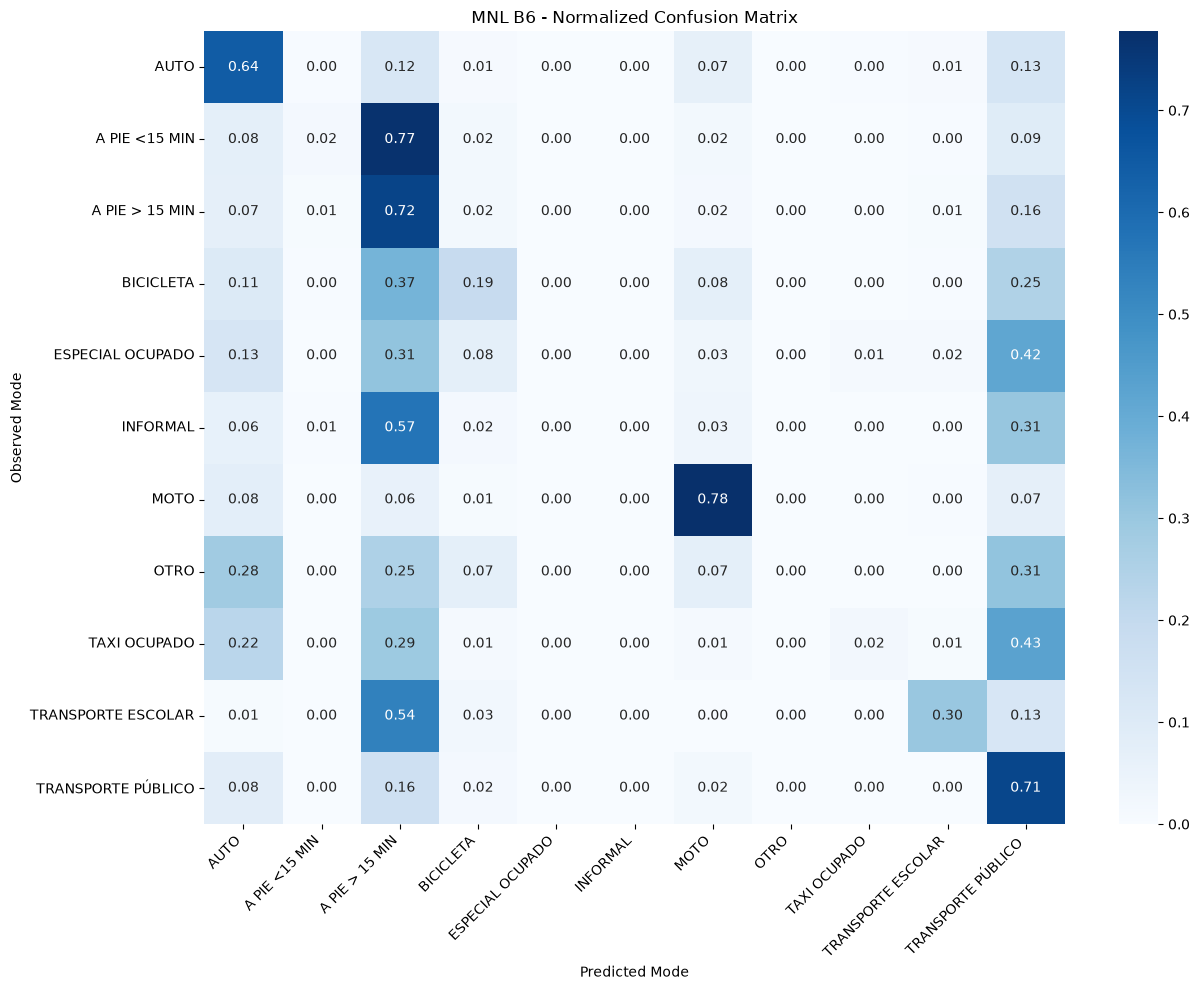

MNL B6 results successfully saved:
Figures:  D:\JAIME_ALEJANDRO_GARCIA\01_ACADEMIC\2026_fall\508_Transportation_planning\Transportatio_Planning\508_TP_Proyect\outputs\figures
Tables:   D:\JAIME_ALEJANDRO_GARCIA\01_ACADEMIC\2026_fall\508_Transportation_planning\Transportatio_Planning\508_TP_Proyect\outputs\tables
Matrices: D:\JAIME_ALEJANDRO_GARCIA\01_ACADEMIC\2026_fall\508_Transportation_planning\Transportatio_Planning\508_TP_Proyect\outputs\matrices


In [21]:
from sklearn.metrics import classification_report

# 1. Save normalized confusion matrix as PNG
plt.figure(figsize=(13, 10))

sns.heatmap(
    b6_confusion,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=mode_categories,
    yticklabels=mode_categories
)

plt.title("MNL B6 - Normalized Confusion Matrix")
plt.xlabel("Predicted Mode")
plt.ylabel("Observed Mode")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

plt.savefig(
    figures_path / "MNL_B6_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# 2. Save normalized confusion matrix as CSV
pd.DataFrame(
    b6_confusion,
    index=mode_categories,
    columns=mode_categories
).to_csv(
    matrices_path / "MNL_B6_confusion_matrix.csv"
)

# 3. Save classification report
report = classification_report(
    y_test,
    b6_test_predictions,
    labels=np.arange(11),
    target_names=mode_categories,
    output_dict=True,
    zero_division=0
)

pd.DataFrame(report).T.to_csv(
    tables_path / "MNL_B6_classification_report.csv"
)

# 4. Save global performance metrics
pd.DataFrame([b6_test_metrics]).to_csv(
    tables_path / "MNL_B6_test_metrics.csv",
    index=False
)

print("MNL B6 results successfully saved:")
print(f"Figures:  {figures_path}")
print(f"Tables:   {tables_path}")
print(f"Matrices: {matrices_path}")

### 1.6 Análisis de coeficientes y pruebas de Wald.

In [22]:
# Inspect stored MNL B6 estimation results

b6_result = mnl_backup["b6_model_result"]
b6_optimization = b6_result["optimization"]

print("MNL B6 ESTIMATION OBJECT")
print("-" * 55)

print("Model result keys:")
print(list(b6_result.keys()))

print("\nOptimization result fields:")
print(list(b6_optimization.keys()))

print("\nParameter information:")
print("Number of coefficients:", len(b6_result["coefficients"]))
print("Number of parameter names:", len(b6_result["parameter_names"]))
print("Converged:", b6_result["converged"])
print("Log-likelihood:", b6_result["log_likelihood"])

print("\nAvailable covariance / Hessian information:")
for key in ["hess_inv", "hess", "cov_params", "covariance", "standard_errors"]:
    if key in b6_result:
        print(f"Result field '{key}':", type(b6_result[key]))
    if key in b6_optimization:
        print(f"Optimization field '{key}':", type(b6_optimization[key]))

MNL B6 ESTIMATION OBJECT
-------------------------------------------------------
Model result keys:
['model_id', 'optimization', 'parameter_map', 'parameter_names', 'coefficients', 'n_parameters', 'log_likelihood', 'AIC', 'BIC', 'converged', 'iterations', 'gradient_norm', 'runtime_seconds']

Optimization result fields:
['fun', 'jac', 'nfev', 'njev', 'nit', 'status', 'message', 'x', 'success', 'hess_inv']

Parameter information:
Number of coefficients: 251
Number of parameter names: 251
Converged: True
Log-likelihood: -108925.27267482685

Available covariance / Hessian information:
Optimization field 'hess_inv': <class 'scipy.optimize._lbfgsb_py.LbfgsInvHessProduct'>


In [23]:
from scipy.stats import norm
from scipy.sparse.linalg import LinearOperator

# 1. Extract estimated coefficients and approximate inverse Hessian
b6_coefficients = np.asarray(b6_result["coefficients"])
hess_inv = b6_optimization["hess_inv"]

# Convert inverse Hessian approximation to a dense matrix
covariance_matrix = hess_inv.todense()

# 2. Calculate standard errors
variances = np.diag(covariance_matrix)

# Protect against small numerical negative values
b6_standard_errors = np.sqrt(np.maximum(variances, 0))

# 3. Calculate Wald statistics and p-values
b6_wald_statistics = (
    b6_coefficients / b6_standard_errors
)

b6_p_values = 2 * norm.sf(np.abs(b6_wald_statistics))

# 4. Calculate 95% confidence intervals
z_critical = norm.ppf(0.975)

ci_lower = b6_coefficients - z_critical * b6_standard_errors
ci_upper = b6_coefficients + z_critical * b6_standard_errors

# 5. Build coefficient results table
b6_coefficient_results = pd.DataFrame({
    "Parameter": b6_result["parameter_names"],
    "Coefficient": b6_coefficients,
    "Standard_Error": b6_standard_errors,
    "Wald_Statistic": b6_wald_statistics,
    "P_Value": b6_p_values,
    "CI_Lower_95": ci_lower,
    "CI_Upper_95": ci_upper
})

# Significance classification
b6_coefficient_results["Significance"] = np.select(
    [
        b6_p_values < 0.01,
        b6_p_values < 0.05,
        b6_p_values < 0.10
    ],
    ["***", "**", "*"],
    default="Not significant"
)

# 6. Save results
b6_coefficient_results.to_csv(
    tables_path / "MNL_B6_coefficient_Wald_results.csv",
    index=False
)

# 7. Display summary
print("MNL B6 - COEFFICIENT AND WALD ANALYSIS")
print("-" * 55)
print("Number of parameters:", len(b6_coefficient_results))
print("Significant at 1%:", (b6_p_values < 0.01).sum())
print("Significant at 5%:", (b6_p_values < 0.05).sum())
print("Significant at 10%:", (b6_p_values < 0.10).sum())
print("Non-significant:", (b6_p_values >= 0.10).sum())

display(b6_coefficient_results.head(15).round(5))

MNL B6 - COEFFICIENT AND WALD ANALYSIS
-------------------------------------------------------
Number of parameters: 251
Significant at 1%: 1
Significant at 5%: 5
Significant at 10%: 8
Non-significant: 243


,Parameter,Coefficient,Standard_Error,Wald_Statistic,P_Value,CI_Lower_95,CI_Upper_95,Significance
0,const__A PIE <15 MIN,3.20305,4.09939,0.78135,0.43460,-4.83162,11.23771,Not significant
1,const__A PIE > 15 MIN,4.59961,4.67527,0.98382,0.32521,-4.56375,13.76298,Not significant
2,const__BICICLETA,0.45990,4.22925,0.10874,0.91341,-7.82927,8.74907,Not significant
3,const__ESPECIAL OCUPADO,-0.36054,5.08473,-0.07091,0.94347,-10.32642,9.60535,Not significant
4,const__INFORMAL,1.43027,8.35833,0.17112,0.86413,-14.95176,17.81230,Not significant
5,const__MOTO,-1.21514,2.55895,-0.47486,0.63489,-6.23060,3.80031,Not significant
6,const__OTRO,-2.09958,10.31032,-0.20364,0.83864,-22.30743,18.10828,Not significant
7,const__TAXI OCUPADO,0.99460,7.74638,0.12840,0.89784,-14.18803,16.17724,Not significant
8,const__TRANSPORTE ESCOLAR,-1.59869,6.04022,-0.26467,0.79126,-13.43729,10.23992,Not significant
9,const__TRANSPORTE PÚBLICO,4.22508,4.89959,0.86233,0.38850,-5.37794,13.82811,Not significant


In [24]:

from scipy.special import softmax
from scipy.stats import norm

# 1. Reconstruct the alternative-specific coefficient matrix
X = X_train_mnl.to_numpy(dtype=float)
parameter_map = b6_result["parameter_map"].to_numpy()
theta = np.asarray(b6_result["coefficients"])

n_features = X.shape[1]
n_alternatives = 10

beta = np.zeros(parameter_map.shape)
valid = parameter_map >= 0
beta[valid] = theta[parameter_map[valid]]

# 2. Calculate choice probabilities
utilities = np.column_stack([np.zeros(len(X)), X @ beta])
P = softmax(utilities, axis=1)[:, 1:]

# 3. Calculate the analytical Hessian
H_full = np.zeros((n_features * n_alternatives,
                   n_features * n_alternatives))

for a in range(n_alternatives):
    for b in range(n_alternatives):
        weights = P[:, a] * ((a == b) - P[:, b])
        block = X.T @ (X * weights[:, None])

        rows = np.arange(n_features) * n_alternatives + a
        cols = np.arange(n_features) * n_alternatives + b
        H_full[np.ix_(rows, cols)] = block

# 4. Extract estimated parameters in their original order
feature_idx, alternative_idx = np.where(valid)
parameter_idx = parameter_map[valid]
order = np.argsort(parameter_idx)

positions = (
    feature_idx[order] * n_alternatives
    + alternative_idx[order]
)

H = H_full[np.ix_(positions, positions)]
H = (H + H.T) / 2

# 5. Calculate covariance and Wald statistics
eigenvalues = np.linalg.eigvalsh(H)

if eigenvalues.min() <= 0:
    raise ValueError(
        "Hessian is not positive definite. "
        "Check numerical stability before inference."
    )

covariance = np.linalg.inv(H)
se = np.sqrt(np.diag(covariance))

z_values = theta / se
p_values = 2 * norm.sf(np.abs(z_values))

results = pd.DataFrame({
    "Parameter": b6_result["parameter_names"],
    "Coefficient": theta,
    "Standard_Error": se,
    "Wald_Statistic": z_values,
    "P_Value": p_values,
    "CI_Lower_95": theta - 1.96 * se,
    "CI_Upper_95": theta + 1.96 * se
})

results["Significance"] = np.select(
    [results["P_Value"] < 0.01,
     results["P_Value"] < 0.05,
     results["P_Value"] < 0.10],
    ["***", "**", "*"],
    default="Not significant"
)

results.to_csv(
    tables_path / "MNL_B6_Wald_results.csv",
    index=False
)

print("MNL B6 - ANALYTICAL WALD RESULTS")
print("-" * 45)
print(f"Parameters: {len(results)}")
print(f"Significant at 1%: {(results['P_Value'] < 0.01).sum()}")
print(f"Significant at 5%: {(results['P_Value'] < 0.05).sum()}")
print(f"Significant at 10%: {(results['P_Value'] < 0.10).sum()}")
print(f"Minimum Hessian eigenvalue: {eigenvalues.min():.6f}")

display(
    results.loc[results["P_Value"] < 0.10]
    .sort_values("P_Value")
    .round(4)
)


MNL B6 - ANALYTICAL WALD RESULTS
---------------------------------------------
Parameters: 251
Significant at 1%: 174
Significant at 5%: 191
Significant at 10%: 199
Minimum Hessian eigenvalue: 0.026659


,Parameter,Coefficient,Standard_Error,Wald_Statistic,P_Value,CI_Lower_95,CI_Upper_95,Significance
110,categorical__vehicle_availability_2+__TRANSPOR...,-2.9016,0.0586,-49.4760,0.0000,-3.0165,-2.7866,***
19,binary__has_car_license__TRANSPORTE PÚBLICO,-1.7116,0.0356,-48.0928,0.0000,-1.7814,-1.6419,***
92,categorical__vehicle_availability_1__A PIE > 1...,-2.2802,0.0559,-40.7806,0.0000,-2.3898,-2.1707,***
15,binary__has_car_license__MOTO,-2.4607,0.0545,-45.1552,0.0000,-2.5675,-2.3539,***
100,categorical__vehicle_availability_1__TRANSPORT...,-2.3848,0.0548,-43.5228,0.0000,-2.4922,-2.2774,***
...,...,...,...,...,...,...,...,...
69,categorical__estra_hg_5__TRANSPORTE ESCOLAR,0.2722,0.1585,1.7178,0.0858,-0.0384,0.5828,*
3,const__ESPECIAL OCUPADO,-0.3605,0.2102,-1.7153,0.0863,-0.7725,0.0514,*
163,categorical__purpose_group_SOCIAL_RELIGIOUS__B...,-0.3626,0.2143,-1.6923,0.0906,-0.7825,0.0573,*
167,categorical__purpose_group_SOCIAL_RELIGIOUS__OTRO,1.2152,0.7253,1.6755,0.0938,-0.2063,2.6368,*


#### 1.6.1 Pruebas de Wald

In [25]:

from scipy.stats import chi2

# 1. Map each estimated parameter to its original explanatory variable
parameter_map_df = b6_result["parameter_map"]
parameter_map_array = parameter_map_df.to_numpy()

parameter_groups = [None] * len(theta)

def get_original_variable(feature_name):
    if feature_name == "const":
        return None

    for variable in b6_features:
        if feature_name in [
            f"binary__{variable}",
            f"numerical__{variable}"
        ]:
            return variable

        if feature_name.startswith(f"categorical__{variable}_"):
            return variable

    return None

for row_idx, feature_name in enumerate(parameter_map_df.index):
    variable = get_original_variable(feature_name)

    if variable is None:
        continue

    for col_idx in range(parameter_map_array.shape[1]):
        parameter_idx = parameter_map_array[row_idx, col_idx]

        if parameter_idx >= 0:
            parameter_groups[int(parameter_idx)] = variable

# 2. Perform joint Wald tests for each explanatory variable
joint_wald_results = []

for variable in b6_features:
    indices = [
        i for i, group in enumerate(parameter_groups)
        if group == variable
    ]

    if not indices:
        continue

    beta_group = theta[indices]
    covariance_group = covariance[np.ix_(indices, indices)]

    statistic = float(
        beta_group @ np.linalg.solve(covariance_group, beta_group)
    )

    degrees_freedom = len(indices)
    p_value = chi2.sf(statistic, degrees_freedom)

    joint_wald_results.append({
        "Variable": variable,
        "Parameters": degrees_freedom,
        "Wald_Chi2": statistic,
        "Degrees_of_Freedom": degrees_freedom,
        "P_Value": p_value,
        "Significance": (
            "***" if p_value < 0.01 else
            "**" if p_value < 0.05 else
            "*" if p_value < 0.10 else
            "Not significant"
        )
    })

joint_wald_df = pd.DataFrame(joint_wald_results)
joint_wald_df = joint_wald_df.sort_values("P_Value")

joint_wald_df.to_csv(
    tables_path / "MNL_B6_joint_Wald_tests.csv",
    index=False
)

print("MNL B6 - JOINT WALD TESTS")
print("-" * 45)
display(joint_wald_df.round(5))


MNL B6 - JOINT WALD TESTS
---------------------------------------------


,Variable,Parameters,Wald_Chi2,Degrees_of_Freedom,P_Value,Significance
0,has_car_license,10,4103.06886,10,0.0,***
1,has_motorcycle_license,1,6690.08910,1,0.0,***
2,sexo,10,1979.78330,10,0.0,***
3,estra_hg,60,4900.95978,60,0.0,***
4,vehicle_availability,20,6058.59740,20,0.0,***
5,purpose_group,70,4120.78410,70,0.0,***
7,edad,10,1706.60287,10,0.0,***
8,zat_centroid_distance_m,10,10568.65650,10,0.0,***
6,time_period_6,50,1477.68481,50,0.0,***


**Joint Wald Tests**

The joint Wald tests indicate that all nine explanatory variables are statistically significant at the 1% level. This suggests that individual characteristics, vehicle availability, socioeconomic conditions, trip purpose, time period, and spatial context jointly contribute to explaining travel mode choice.

Distance to the ZAT centroid presents the largest Wald statistic, followed by motorcycle license and vehicle availability. These results highlight the relevance of spatial and mobility-related characteristics in the mode choice process. However, Wald statistics should not be interpreted directly as measures of relative predictive importance or causal effects.

#### 1.6.2 Coefientes Por modo

MNL B6 - COEFFICIENTS BY MODE
Significance: *** p<0.01 | ** p<0.05 | * p<0.10


,A PIE <15 MIN,A PIE > 15 MIN,BICICLETA,ESPECIAL OCUPADO,INFORMAL,MOTO,OTRO,TAXI OCUPADO,TRANSPORTE ESCOLAR,TRANSPORTE PÚBLICO
const,3.203***,4.600***,0.460***,-0.361*,1.430***,-1.215***,-2.100***,0.995***,-1.599***,4.225***
binary__has_car_license,-1.804***,-1.821***,-2.364***,-1.349***,-2.142***,-2.461***,-1.421***,-1.294***,-2.378***,-1.712***
binary__has_motorcycle_license,—,—,—,—,—,3.862***,—,—,—,—
categorical__sexo_Intersexual,—,—,—,—,—,—,—,—,—,—
categorical__sexo_Mujer,0.424***,0.276***,-1.120***,0.292***,0.170**,-0.368***,-1.071***,0.446***,0.153**,0.387***
categorical__estra_hg_2,0.166**,-0.087,0.513***,0.737***,-0.633***,-0.242***,-0.109,0.540***,-0.111,-0.109
categorical__estra_hg_3,-0.551***,-0.899***,-0.236***,0.445***,-2.048***,-0.896***,-0.732***,0.262**,-0.384***,-0.706***
categorical__estra_hg_4,-1.184***,-1.457***,-0.971***,0.817***,-3.064***,-1.594***,-0.773***,0.438***,0.456***,-1.151***
categorical__estra_hg_5,-1.583***,-1.755***,-1.594***,0.612***,-8.052,-1.834***,-0.762**,0.194,0.272*,-1.931***
categorical__estra_hg_6,-2.230***,-2.309***,-1.748***,0.189,-3.757***,-2.093***,-2.573***,0.105,-0.108,-3.297***


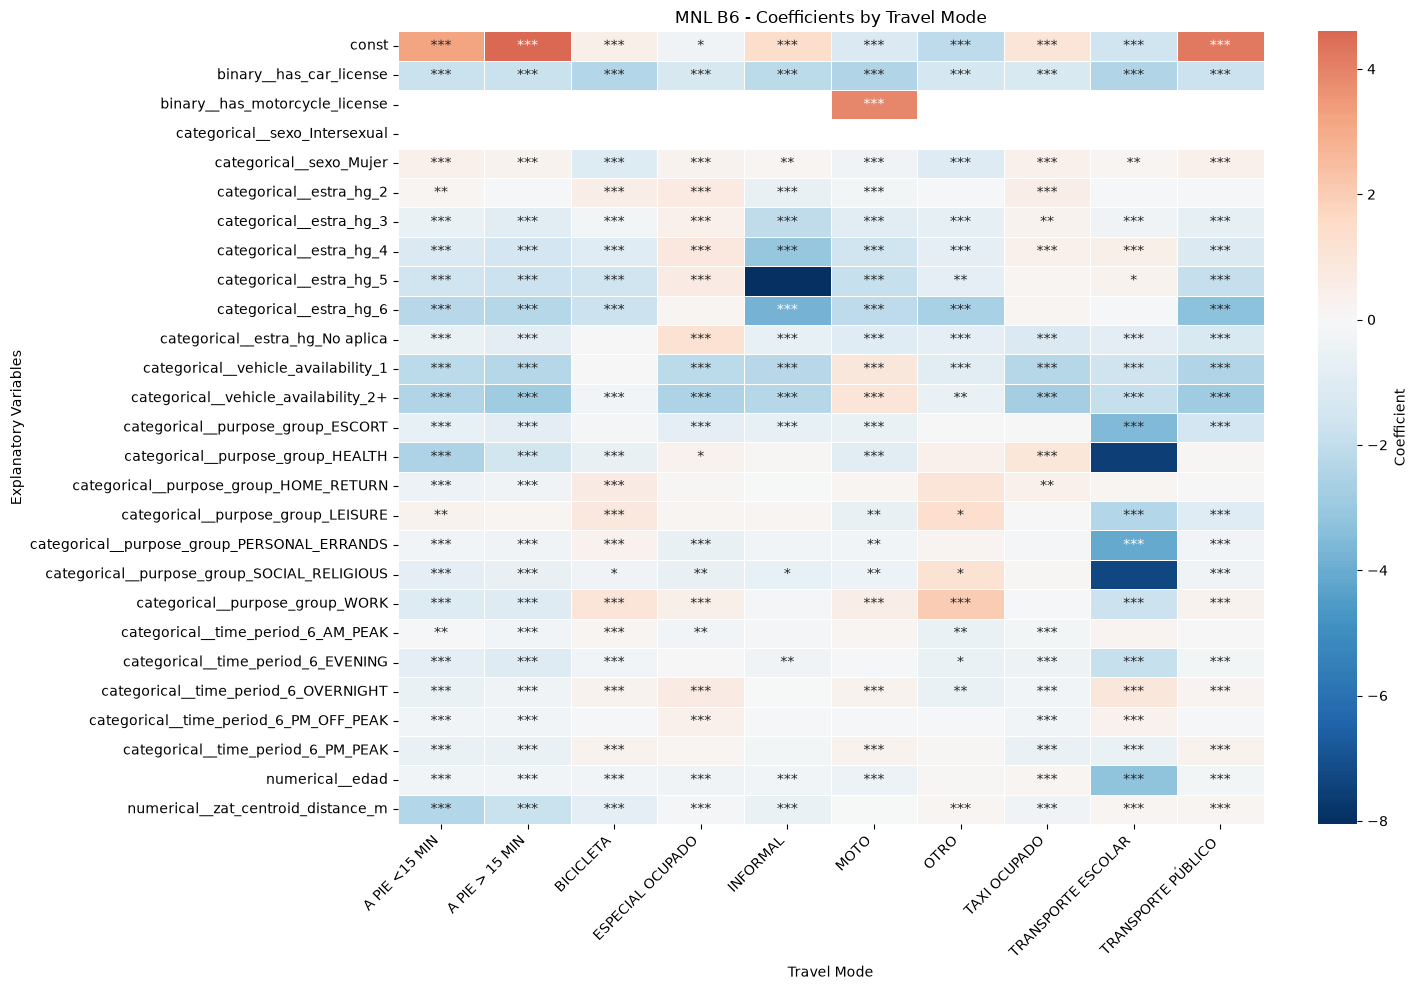

In [26]:

# 1. Build coefficient and p-value matrices
parameter_map_df = b6_result["parameter_map"]

coefficient_matrix = pd.DataFrame(
    np.nan,
    index=parameter_map_df.index,
    columns=parameter_map_df.columns
)

pvalue_matrix = coefficient_matrix.copy()

for feature in parameter_map_df.index:
    for mode in parameter_map_df.columns:
        idx = parameter_map_df.loc[feature, mode]

        if idx >= 0:
            coefficient_matrix.loc[feature, mode] = theta[int(idx)]
            pvalue_matrix.loc[feature, mode] = results.iloc[int(idx)]["P_Value"]

# 2. Create significance annotations
significance_matrix = pvalue_matrix.map(
    lambda p: (
        "***" if pd.notna(p) and p < 0.01 else
        "**" if pd.notna(p) and p < 0.05 else
        "*" if pd.notna(p) and p < 0.10 else ""
    )
)

# 3. Create formatted coefficient table
formatted_matrix = coefficient_matrix.copy().astype(object)

for row in coefficient_matrix.index:
    for col in coefficient_matrix.columns:
        value = coefficient_matrix.loc[row, col]
        if pd.notna(value):
            formatted_matrix.loc[row, col] = (
                f"{value:.3f}{significance_matrix.loc[row, col]}"
            )
        else:
            formatted_matrix.loc[row, col] = "—"

# 4. Save results
coefficient_matrix.to_csv(
    tables_path / "MNL_B6_coefficients_by_mode.csv"
)
formatted_matrix.to_csv(
    tables_path / "MNL_B6_coefficients_by_mode_formatted.csv"
)

# 5. Display coefficient matrix
print("MNL B6 - COEFFICIENTS BY MODE")
print("Significance: *** p<0.01 | ** p<0.05 | * p<0.10")
display(formatted_matrix)

# 6. Plot heatmap
plt.figure(figsize=(15, 10))

sns.heatmap(
    coefficient_matrix,
    annot=significance_matrix,
    fmt="",
    cmap="RdBu_r",
    center=0,
    linewidths=0.4,
    cbar_kws={"label": "Coefficient"}
)

plt.title("MNL B6 - Coefficients by Travel Mode")
plt.xlabel("Travel Mode")
plt.ylabel("Explanatory Variables")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

plt.savefig(
    figures_path / "MNL_B6_coefficients_by_mode.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


Hay varios patrones que vale la pena destacar.
Hallazgos principales
Licencia de automóvil

Todos los coeficientes son negativos y estadísticamente significativos. Esto indica que tener licencia de automóvil está asociado con una menor utilidad relativa de las alternativas frente a AUTO. Es un resultado coherente con la elección modal, aunque no implica necesariamente que la persona tenga o utilice un automóvil.

Licencia de motocicleta

El coeficiente para MOTO es positivo (3.862) y altamente significativo. Es uno de los resultados más claros del modelo: tener licencia de motocicleta está fuertemente asociado con la elección de este modo frente a AUTO.

Disponibilidad de vehículos

Los coeficientes para disponibilidad de uno o más vehículos son negativos en casi todas las alternativas, mientras que son positivos para MOTO. Esto sugiere diferencias importantes en la relación entre disponibilidad de vehículos y elección modal.

Sexo

La categoría Mujer presenta coeficientes positivos para caminar, transporte público, taxi y transporte especial ocupado, pero negativos para bicicleta, motocicleta y otros modos. Es un patrón interesante de diferencias en las preferencias modales estimadas.

Estrato socioeconómico

Se observan diferencias importantes entre categorías. Por ejemplo, los coeficientes de los estratos 3 a 6 son generalmente negativos para caminar y transporte público, mientras que algunas alternativas presentan asociaciones positivas. Esto merece una interpretación cuidadosa frente a la categoría de referencia.

Propósito del viaje

Es una de las variables que muestra mayor heterogeneidad entre modos. Por ejemplo, el propósito WORK presenta coeficientes positivos para bicicleta, transporte especial ocupado, motocicleta y otros modos, pero negativos para caminar.

Distancia al centroide ZAT

Los coeficientes son negativos para caminar, bicicleta y varias alternativas motorizadas, pero positivos para otros modos, transporte escolar y transporte público. Es especialmente interesante para conectar el modelo con la dimensión espacial de nuestra investigación.
Dos precauciones para la interpretación
- Los coeficientes representan cambios en la utilidad relativa frente a AUTO, no cambios directos en la probabilidad de elegir un modo.
- Las variables categóricas se interpretan respecto a sus categorías de referencia. Además, edad y zat_centroid_distance_m fueron estandarizadas, por lo que sus coeficientes corresponden a cambios de una desviación estándar, no a un año o un metro.
También debemos revisar algunos coeficientes extremos, como los de estrato 5 para INFORMAL y propósito HEALTH para TRANSPORTE ESCOLAR. Sus magnitudes pueden reflejar categorías con pocas observaciones o problemas de separación, por lo que no conviene darles una interpretación sustantiva sin revisar sus frecuencias.
Mi recomendación
No describiría los 251 coeficientes en el informe. Seleccionaría estos cinco temas para la discusión:
1. Licencias y disponibilidad de vehículos.
2. Diferencias socioeconómicas en la elección modal.
3. Diferencias por sexo.
4. Propósito del viaje.
5. Distancia y contexto espacial.

Coefficient Analysis and Behavioral Interpretation

The coefficient matrix reveals substantial heterogeneity in the relationships between individual, socioeconomic, and trip characteristics and travel mode choice.

Vehicle Licenses and Availability

Car license ownership presents negative and statistically significant coefficients across all non-auto alternatives, indicating a higher relative utility of AUTO among individuals holding a car license. Conversely, motorcycle license ownership has a strong positive association with MOTO (β = 3.862). Vehicle availability also shows predominantly negative coefficients across alternatives, with positive associations for motorcycle choice.

Socioeconomic and Demographic Characteristics

Gender differences are evident across travel modes. The female category presents positive coefficients for walking, public transport, taxi, and special occupied transport, while coefficients are negative for bicycle and motorcycle. Socioeconomic strata also exhibit heterogeneous patterns, particularly for walking and public transport, suggesting differences in modal preferences across socioeconomic groups.

Trip Purpose and Temporal Characteristics

Trip purpose is associated with substantial variation across alternatives. Work-related trips, for example, show positive coefficients for bicycle, motorcycle, and other modes, but negative coefficients for walking. Time-of-day effects also vary across alternatives, highlighting the relevance of temporal context in travel mode choice.

Spatial Context

Distance to the ZAT centroid presents negative and statistically significant coefficients for walking, bicycle, and several other alternatives, while positive coefficients are observed for public transport, school transport, and other modes. This highlights the importance of spatial context in explaining modal choice.

Overall Interpretation and Limitations

The results indicate that travel mode choice is associated with a combination of mobility resources, socioeconomic characteristics, trip purpose, temporal conditions, and spatial context. However, coefficients represent changes in relative utility compared with AUTO, rather than direct changes in choice probabilities. Numerical variables were standardized, so their coefficients represent changes per standard deviation. Extreme estimates in some categories should be interpreted cautiously, particularly where sparse observations or separation may be present. These relationships should be understood as statistical associations rather than causal effects.

#### 1.6.3 Average Marginal Effects (AME)

In [27]:

from scipy.special import softmax
from scipy.sparse import issparse

# 1. Reconstruct the coefficient matrix
parameter_map_df = b6_result["parameter_map"]
parameter_map = parameter_map_df.to_numpy()

beta = np.zeros(parameter_map.shape)
valid = parameter_map >= 0
beta[valid] = theta[parameter_map[valid]]

# 2. Define a function to obtain choice probabilities
def predict_b6_probabilities(X):
    utilities = np.column_stack([
        np.zeros(len(X)),
        X @ beta
    ])
    return softmax(utilities, axis=1)

def transform_counterfactual(data):
    transformed = b6_preprocessor.transform(data)
    if issparse(transformed):
        transformed = transformed.toarray()
    return np.column_stack([
        np.ones(len(data)),
        transformed
    ])

# 3. Calculate baseline probabilities on the test sample
X_base = X_test_mnl.to_numpy(dtype=float)
P_base = predict_b6_probabilities(X_base)

ame_rows = []

# 4. Binary variables: discrete change from 0 to 1
for variable in binary_features:
    counterfactual = X_test_b6.copy()
    counterfactual[variable] = 1

    P_cf = predict_b6_probabilities(
        transform_counterfactual(counterfactual)
    )

    effects = (P_cf - P_base).mean(axis=0)

    for mode, effect in zip(["AUTO"] + mode_categories[1:], effects):
        ame_rows.append({
            "Variable": variable,
            "Contrast": "1 vs 0",
            "Mode": mode,
            "AME": effect
        })

# 5. Categorical variables: compare each level with its reference
encoder = b6_preprocessor.named_transformers_["categorical"]

for variable, categories in zip(categorical_features, encoder.categories_):
    reference = categories[0]

    for category in categories[1:]:
        counterfactual = X_test_b6.copy()
        counterfactual[variable] = category

        P_cf = predict_b6_probabilities(
            transform_counterfactual(counterfactual)
        )

        effects = (P_cf - P_base).mean(axis=0)

        for mode, effect in zip(["AUTO"] + mode_categories[1:], effects):
            ame_rows.append({
                "Variable": variable,
                "Contrast": f"{category} vs {reference}",
                "Mode": mode,
                "AME": effect
            })

# 6. Continuous variables: analytical derivative per standard deviation
for variable in numerical_features:
    feature_name = f"numerical__{variable}"
    feature_idx = list(parameter_map_df.index).index(feature_name)

    # Include AUTO as the reference alternative
    alternative_betas = np.concatenate([
        [0.0],
        beta[feature_idx, :]
    ])

    weighted_beta = P_base @ alternative_betas

    derivatives = (
        P_base * (alternative_betas[None, :] - weighted_beta[:, None])
    )

    effects = derivatives.mean(axis=0)

    for mode, effect in zip(["AUTO"] + mode_categories[1:], effects):
        ame_rows.append({
            "Variable": variable,
            "Contrast": "Per 1 standard deviation",
            "Mode": mode,
            "AME": effect
        })

# 7. Create and save results
ame_results = pd.DataFrame(ame_rows)
ame_results["AME_percentage_points"] = ame_results["AME"] * 100

ame_results.to_csv(
    tables_path / "MNL_B6_average_marginal_effects.csv",
    index=False
)

ame_pivot = ame_results.pivot_table(
    index=["Variable", "Contrast"],
    columns="Mode",
    values="AME_percentage_points"
)

ame_pivot.to_csv(
    tables_path / "MNL_B6_AME_by_mode.csv"
)

print("MNL B6 - AVERAGE MARGINAL EFFECTS")
print("-" * 50)
print(f"Test observations: {len(X_base):,}")
print(f"Number of contrasts: {ame_results.groupby(['Variable', 'Contrast']).ngroups}")
print("Values are average changes in choice probability (percentage points).")

display(ame_pivot.round(3))


MNL B6 - AVERAGE MARGINAL EFFECTS
--------------------------------------------------
Test observations: 20,029
Number of contrasts: 26
Values are average changes in choice probability (percentage points).


Mode                                                   A PIE <15 MIN  \
Variable                Contrast                                       
edad                    Per 1 standard deviation              -0.170   
estra_hg                2 vs 1                                 0.936   
                        3 vs 1                                 0.280   
                        4 vs 1                                -2.215   
                        5 vs 1                                -2.558   
                        6 vs 1                                -3.913   
                        No aplica vs 1                         1.770   
has_car_license         1 vs 0                                -1.110   
has_motorcycle_license  1 vs 0                                -2.655   
purpose_group           ESCORT vs EDUCATION                    5.717   
                        HEALTH vs EDUCATION                   -9.115   
                        HOME_RETURN vs EDUCATION              -0.469   
                        LEISURE vs EDUCATION                   7.279   
                        PERSONAL_ERRANDS vs EDUCATION          3.768   
                        SOCIAL_RELIGIOUS vs EDUCATION          0.311   
                        WORK vs EDUCATION                     -3.872   
sexo                    Intersexual vs Hombre                 -1.527   
                        Mujer vs Hombre                        1.164   
time_period_6           AM_PEAK vs AM_OFF_PEAK                 1.694   
                        EVENING vs AM_OFF_PEAK                -0.070   
                        OVERNIGHT vs AM_OFF_PEAK              -2.878   
                        PM_OFF_PEAK vs AM_OFF_PEAK             0.589   
                        PM_PEAK vs AM_OFF_PEAK                -1.935   
vehicle_availability    1 vs 0                                -0.462   
                        2+ vs 0                                0.718   
zat_centroid_distance_m Per 1 standard deviation             -13.365   

Mode                                                   A PIE > 15 MIN    AUTO  \
Variable                Contrast                                                
edad                    Per 1 standard deviation                0.590   2.161   
estra_hg                2 vs 1                                  2.066  -5.457   
                        3 vs 1                                 -1.652  -1.158   
                        4 vs 1                                 -4.959   2.529   
                        5 vs 1                                 -3.353   7.186   
                        6 vs 1                                 -4.252  14.140   
                        No aplica vs 1                          1.779   0.305   
has_car_license         1 vs 0                                 -2.513   9.959   
has_motorcycle_license  1 vs 0                                 -5.001  -3.525   
purpose_group           ESCORT vs EDUCATION                     3.907   6.226   
                        HEALTH vs EDUCATION                    -9.451   3.231   
                        HOME_RETURN vs EDUCATION                1.243  -0.447   
                        LEISURE vs EDUCATION                   11.307   0.145   
                        PERSONAL_ERRANDS vs EDUCATION           4.041   1.506   
                        SOCIAL_RELIGIOUS vs EDUCATION           3.952   3.066   
                        WORK vs EDUCATION                      -8.029  -0.156   
sexo                    Intersexual vs Hombre                  -0.769   0.538   
                        Mujer vs Hombre                         0.758  -0.535   
time_period_6           AM_PEAK vs AM_OFF_PEAK                  0.198  -0.152   
                        EVENING vs AM_OFF_PEAK                 -5.244   3.127   
                        OVERNIGHT vs AM_OFF_PEAK               -1.603  -0.539   
                        PM_OFF_PEAK vs AM_OFF_PEAK              1.645   0.275   
                        PM_PEAK vs AM_O

In [28]:

# Correct average discrete changes for binary and categorical variables

correct_ame_rows = []

# Binary variables: compare 1 against 0
for variable in binary_features:
    scenario_0 = X_test_b6.copy()
    scenario_1 = X_test_b6.copy()

    scenario_0[variable] = 0
    scenario_1[variable] = 1

    P_0 = predict_b6_probabilities(
        transform_counterfactual(scenario_0)
    )
    P_1 = predict_b6_probabilities(
        transform_counterfactual(scenario_1)
    )

    effects = (P_1 - P_0).mean(axis=0)

    for mode, effect in zip(["AUTO"] + mode_categories[1:], effects):
        correct_ame_rows.append({
            "Variable": variable,
            "Contrast": "1 vs 0",
            "Mode": mode,
            "AME_pp": effect * 100
        })

# Categorical variables: compare each category against its reference
encoder = b6_preprocessor.named_transformers_["categorical"]

for variable, categories in zip(categorical_features, encoder.categories_):
    reference = categories[0]

    for category in categories[1:]:
        scenario_ref = X_test_b6.copy()
        scenario_cat = X_test_b6.copy()

        scenario_ref[variable] = reference
        scenario_cat[variable] = category

        P_ref = predict_b6_probabilities(
            transform_counterfactual(scenario_ref)
        )
        P_cat = predict_b6_probabilities(
            transform_counterfactual(scenario_cat)
        )

        effects = (P_cat - P_ref).mean(axis=0)

        for mode, effect in zip(["AUTO"] + mode_categories[1:], effects):
            correct_ame_rows.append({
                "Variable": variable,
                "Contrast": f"{category} vs {reference}",
                "Mode": mode,
                "AME_pp": effect * 100
            })

# Continuous variables: retain the analytical derivative per standard deviation
for variable in numerical_features:
    feature_idx = list(parameter_map_df.index).index(
        f"numerical__{variable}"
    )

    alternative_betas = np.concatenate([[0.0], beta[feature_idx, :]])
    weighted_beta = P_base @ alternative_betas

    derivatives = P_base * (
        alternative_betas[None, :] - weighted_beta[:, None]
    )

    effects = derivatives.mean(axis=0)

    for mode, effect in zip(["AUTO"] + mode_categories[1:], effects):
        correct_ame_rows.append({
            "Variable": variable,
            "Contrast": "Per 1 standard deviation",
            "Mode": mode,
            "AME_pp": effect * 100
        })

# Save and display corrected results
correct_ame = pd.DataFrame(correct_ame_rows)

correct_ame.to_csv(
    tables_path / "MNL_B6_AME_corrected.csv",
    index=False
)

correct_ame_pivot = correct_ame.pivot_table(
    index=["Variable", "Contrast"],
    columns="Mode",
    values="AME_pp"
)

correct_ame_pivot.to_csv(
    tables_path / "MNL_B6_AME_corrected_by_mode.csv"
)

print("MNL B6 - CORRECTED AVERAGE MARGINAL EFFECTS")
print("Values in percentage points")
display(correct_ame_pivot.round(3))


MNL B6 - CORRECTED AVERAGE MARGINAL EFFECTS
Values in percentage points


Mode                                                   A PIE <15 MIN  \
Variable                Contrast                                       
edad                    Per 1 standard deviation              -0.170   
estra_hg                2 vs 1                                 2.021   
                        3 vs 1                                 1.365   
                        4 vs 1                                -1.130   
                        5 vs 1                                -1.473   
                        6 vs 1                                -2.828   
                        No aplica vs 1                         2.855   
has_car_license         1 vs 0                                -1.688   
has_motorcycle_license  1 vs 0                                -2.964   
purpose_group           ESCORT vs EDUCATION                    2.198   
                        HEALTH vs EDUCATION                  -12.633   
                        HOME_RETURN vs EDUCATION              -3.988   
                        LEISURE vs EDUCATION                   3.761   
                        PERSONAL_ERRANDS vs EDUCATION          0.250   
                        SOCIAL_RELIGIOUS vs EDUCATION         -3.208   
                        WORK vs EDUCATION                     -7.390   
sexo                    Intersexual vs Hombre                  0.000   
                        Mujer vs Hombre                        2.690   
time_period_6           AM_PEAK vs AM_OFF_PEAK                -0.052   
                        EVENING vs AM_OFF_PEAK                -1.817   
                        OVERNIGHT vs AM_OFF_PEAK              -4.624   
                        PM_OFF_PEAK vs AM_OFF_PEAK            -1.157   
                        PM_PEAK vs AM_OFF_PEAK                -3.682   
vehicle_availability    1 vs 0                                -1.567   
                        2+ vs 0                               -0.387   
zat_centroid_distance_m Per 1 standard deviation             -13.365   

Mode                                                   A PIE > 15 MIN    AUTO  \
Variable                Contrast                                                
edad                    Per 1 standard deviation                0.590   2.161   
estra_hg                2 vs 1                                 -2.308   0.034   
                        3 vs 1                                 -6.026   4.334   
                        4 vs 1                                 -9.334   8.020   
                        5 vs 1                                 -7.728  12.677   
                        6 vs 1                                 -8.626  19.631   
                        No aplica vs 1                         -2.595   5.796   
has_car_license         1 vs 0                                 -3.717  16.547   
has_motorcycle_license  1 vs 0                                 -5.627  -4.595   
purpose_group           ESCORT vs EDUCATION                    -2.076   6.994   
                        HEALTH vs EDUCATION                   -15.434   3.999   
                        HOME_RETURN vs EDUCATION               -4.740   0.321   
                        LEISURE vs EDUCATION                    5.324   0.913   
                        PERSONAL_ERRANDS vs EDUCATION          -1.943   2.274   
                        SOCIAL_RELIGIOUS vs EDUCATION          -2.031   3.834   
                        WORK vs EDUCATION                     -14.013   0.612   
sexo                    Intersexual vs Hombre                   0.000   0.000   
                        Mujer vs Hombre                         1.526  -1.073   
time_period_6           AM_PEAK vs AM_OFF_PEAK                 -3.916   0.472   
                        EVENING vs AM_OFF_PEAK                 -9.358   3.751   
                        OVERNIGHT vs AM_OFF_PEAK               -5.717   0.085   
                        PM_OFF_PEAK vs AM_OFF_PEAK             -2.469   0.900   
                        PM_PEAK vs AM_O

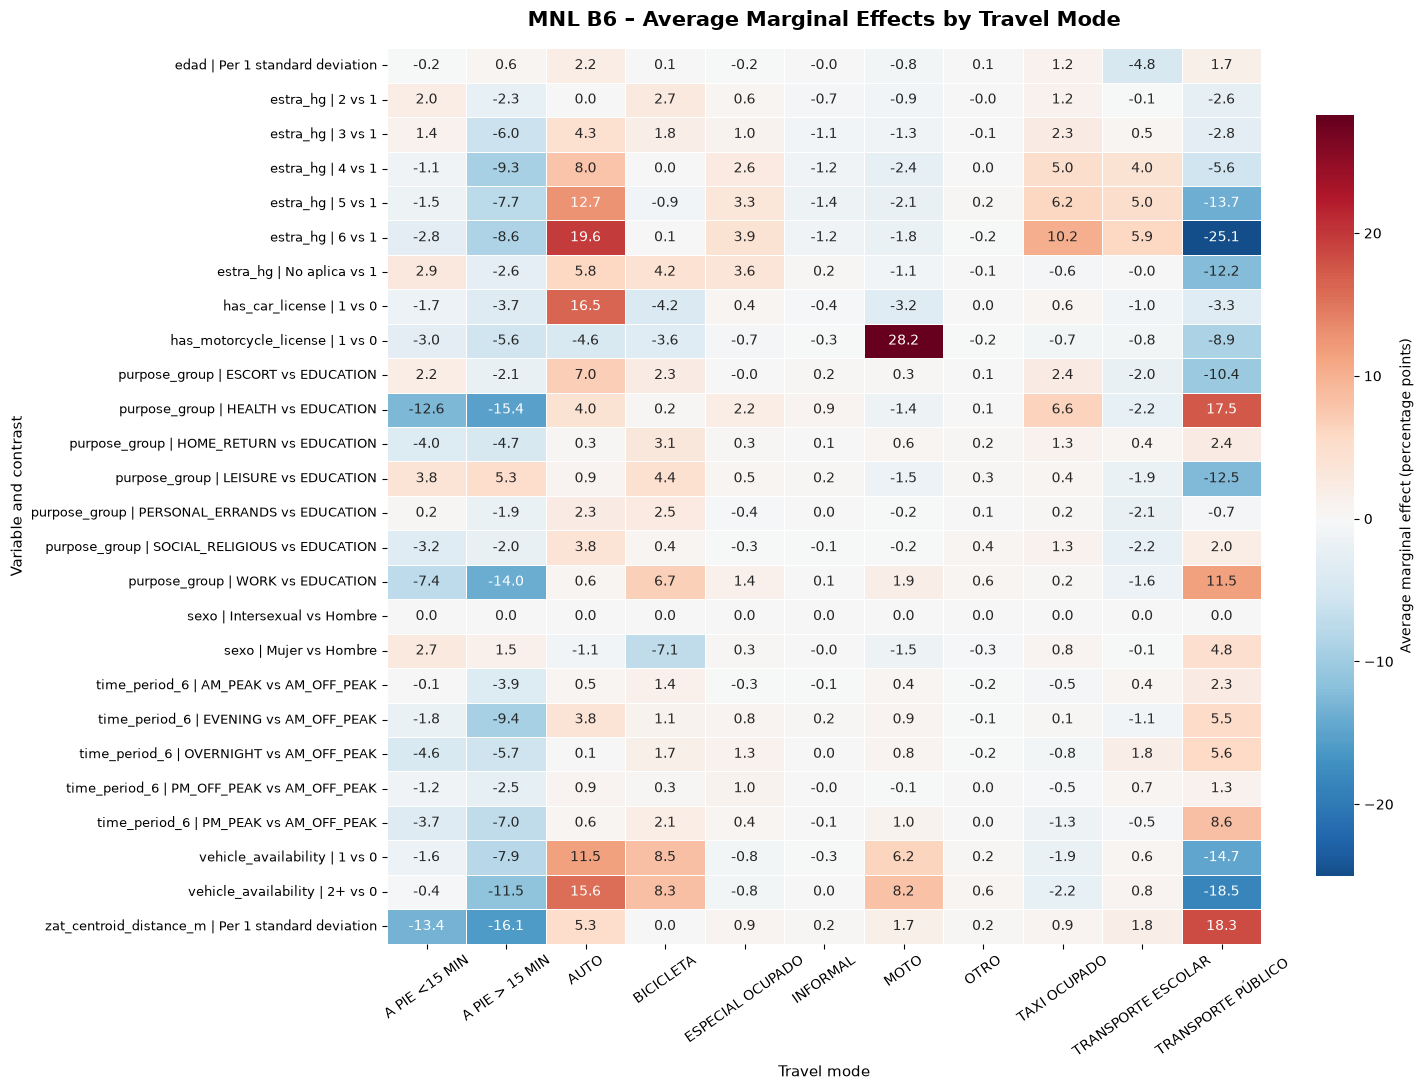

In [29]:
# ============================================================
# MNL B6: Heatmap of corrected Average Marginal Effects
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

# Prepare the corrected AME matrix
ame_heatmap = correct_ame_pivot.copy()

# Create readable row labels
ame_heatmap.index = [
    f"{variable} | {contrast}"
    for variable, contrast in ame_heatmap.index
]

# Plot heatmap
fig, ax = plt.subplots(figsize=(15, 11))

sns.heatmap(
    ame_heatmap,
    cmap="RdBu_r",
    center=0,
    annot=True,
    fmt=".1f",
    linewidths=0.4,
    linecolor="white",
    cbar_kws={
        "label": "Average marginal effect (percentage points)",
        "shrink": 0.85
    },
    ax=ax
)

ax.set_title(
    "MNL B6 – Average Marginal Effects by Travel Mode",
    fontsize=15,
    fontweight="bold",
    pad=16
)

ax.set_xlabel("Travel mode", fontsize=11)
ax.set_ylabel("Variable and contrast", fontsize=11)

ax.tick_params(axis="x", rotation=35)
ax.tick_params(axis="y", labelsize=9)

plt.tight_layout()

# Save figure
figures_path.mkdir(parents=True, exist_ok=True)

plt.savefig(
    figures_path / "MNL_B6_AME_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [30]:
# ============================================================
# MNL B6: Display and export corrected AME results
# ============================================================

# Create a readable results table
ame_results = correct_ame_pivot.copy()

ame_results.index = [
    f"{variable} | {contrast}"
    for variable, contrast in ame_results.index
]

# Display results in percentage points
ame_results = ame_results.round(3)

display(ame_results)

# Export results
ame_results.to_csv(
    tables_path / "MNL_B6_corrected_AME_results.csv",
    encoding="utf-8-sig"
)

print(f"AME results saved to: {tables_path / 'MNL_B6_corrected_AME_results.csv'}")

Mode,A PIE <15 MIN,A PIE > 15 MIN,AUTO,BICICLETA,ESPECIAL OCUPADO,INFORMAL,MOTO,OTRO,TAXI OCUPADO,TRANSPORTE ESCOLAR,TRANSPORTE PÚBLICO
edad | Per 1 standard deviation,-0.170,0.590,2.161,0.091,-0.156,-0.004,-0.763,0.104,1.208,-4.760,1.698
estra_hg | 2 vs 1,2.021,-2.308,0.034,2.717,0.601,-0.655,-0.913,-0.037,1.223,-0.127,-2.557
estra_hg | 3 vs 1,1.365,-6.026,4.334,1.804,0.988,-1.074,-1.279,-0.071,2.276,0.479,-2.796
estra_hg | 4 vs 1,-1.130,-9.334,8.020,0.035,2.580,-1.239,-2.414,0.031,5.022,4.018,-5.590
estra_hg | 5 vs 1,-1.473,-7.728,12.677,-0.922,3.333,-1.419,-2.128,0.206,6.159,5.006,-13.712
estra_hg | 6 vs 1,-2.828,-8.626,19.631,0.118,3.893,-1.185,-1.818,-0.233,10.233,5.873,-25.059
estra_hg | No aplica vs 1,2.855,-2.595,5.796,4.162,3.567,0.234,-1.064,-0.053,-0.610,-0.049,-12.243
has_car_license | 1 vs 0,-1.688,-3.717,16.547,-4.218,0.390,-0.360,-3.211,0.006,0.629,-1.047,-3.331
has_motorcycle_license | 1 vs 0,-2.964,-5.627,-4.595,-3.554,-0.671,-0.268,28.243,-0.172,-0.705,-0.793,-8.893
purpose_group | ESCORT vs EDUCATION,2.198,-2.076,6.994,2.320,-0.010,0.212,0.293,0.094,2.392,-2.012,-10.405


AME results saved to: D:\JAIME_ALEJANDRO_GARCIA\01_ACADEMIC\2026_fall\508_Transportation_planning\Transportatio_Planning\508_TP_Proyect\outputs\tables\MNL_B6_corrected_AME_results.csv


Average Marginal Effects (AME) del modelo MNL B6.

Con esta tabla podemos hacer una interpretación más precisa y seleccionar los resultados más relevantes para el informe.

Hallazgos principales
Variable	Resultado	Interpretación
Distancia al centroide ZAT	+18.28 pp en transporte público	Una desviación estándar adicional está asociada con una mayor probabilidad de elegir transporte público.
Distancia al centroide ZAT	-13.37 pp y -16.10 pp caminando	Disminuye la probabilidad de elegir viajes a pie, tanto cortos como largos.
Estrato 6 vs. estrato 1	+19.63 pp en AUTO	La probabilidad de elegir automóvil aumenta considerablemente.
Estrato 6 vs. estrato 1	-25.06 pp en transporte público	Se observa una reducción importante en la probabilidad de elegir transporte público.
Licencia de automóvil	+16.55 pp en AUTO	Tener licencia está asociado con una mayor probabilidad de elegir automóvil.
Licencia de motocicleta	+28.24 pp en MOTO	Es uno de los efectos positivos más grandes del modelo.
Disponibilidad de 2+ vehículos	+15.56 pp en AUTO	Una mayor disponibilidad vehicular favorece la elección del automóvil.
Disponibilidad de 2+ vehículos	-18.49 pp en transporte público	Se reduce la probabilidad de elegir transporte público.

Efectos del propósito del viaje

También aparecen diferencias interesantes:
- HEALTH: +17.55 pp en transporte público.
- WORK: +11.54 pp en transporte público y +6.65 pp en bicicleta.
- LEISURE: +3.76 pp caminando menos de 15 minutos y +5.32 pp caminando más de 15 minutos.
- ESCORT: -10.41 pp en transporte público.
Estos resultados muestran que el propósito del viaje está relacionado con patrones de elección modal diferentes.

Efectos temporales

Los periodos EVENING y OVERNIGHT presentan incrementos en la probabilidad de transporte público respecto a AM_OFF_PEAK:
- EVENING: +5.48 pp.
- OVERNIGHT: +5.60 pp.
- PM_PEAK: +8.60 pp.
Aspectos que debemos revisar antes de cerrar el análisis

Hay dos puntos metodológicos importantes:
1. sexo | Intersexual vs Hombre presenta exactamente cero en todas las alternativas. Debemos revisar si la categoría tiene observaciones suficientes y cómo fue estimada. No debemos interpretarlo como evidencia de ausencia de diferencias.
2. Los AME no incluyen intervalos de confianza ni errores estándar en esta tabla. Por tanto, todavía no podemos afirmar que cada efecto sea estadísticamente significativo.

In [34]:

# ============================================================
# MNL B6: Delta-method inference for discrete AMEs
# ============================================================

from scipy.stats import norm

# Recover parameter mapping and covariance matrix
parameter_map_array = parameter_map_df.to_numpy()
n_parameters = len(theta)
n_observations = len(X_test_b6)

ame_inference_rows = []

def probability_gradient(X_scenario, probabilities):
    """Calculate probability gradients using the restricted parameter map."""

    X_array = np.asarray(X_scenario, dtype=float)
    n_features = X_array.shape[1]
    n_modes = probabilities.shape[1]

    gradient = np.zeros((n_modes, n_parameters))

    for feature in range(n_features):
        for alternative in range(1, n_modes):

            parameter_idx = parameter_map_array[feature, alternative - 1]

            if parameter_idx < 0:
                continue

            for mode in range(n_modes):

                weights = probabilities[:, mode] * (
                    (mode == alternative) - probabilities[:, alternative]
                )

                # Accumulate contributions from parameters shared across alternatives
                gradient[mode, parameter_idx] += np.mean(
                    X_array[:, feature] * weights
                )

    return gradient


# Binary variables
for variable in binary_features:

    scenario_0 = X_test_b6.copy()
    scenario_1 = X_test_b6.copy()

    scenario_0[variable] = 0
    scenario_1[variable] = 1

    X_0 = transform_counterfactual(scenario_0)
    X_1 = transform_counterfactual(scenario_1)

    P_0 = predict_b6_probabilities(X_0)
    P_1 = predict_b6_probabilities(X_1)

    G_0 = probability_gradient(X_0, P_0)
    G_1 = probability_gradient(X_1, P_1)

    ame = (P_1 - P_0).mean(axis=0) * 100
    gradient = (G_1 - G_0) * 100

    for mode_idx, mode in enumerate(["AUTO"] + mode_categories[1:]):

        variance = (
            gradient[mode_idx] @ covariance @ gradient[mode_idx]
        )

        standard_error = np.sqrt(max(variance, 0))
        z_statistic = ame[mode_idx] / standard_error
        p_value = 2 * norm.sf(abs(z_statistic))

        ame_inference_rows.append({
            "Variable": variable,
            "Contrast": "1 vs 0",
            "Mode": mode,
            "AME_pp": ame[mode_idx],
            "SE": standard_error,
            "CI_Lower_95": ame[mode_idx] - 1.96 * standard_error,
            "CI_Upper_95": ame[mode_idx] + 1.96 * standard_error,
            "P_Value": p_value
        })


# Categorical variables
encoder = b6_preprocessor.named_transformers_["categorical"]

for variable, categories in zip(categorical_features, encoder.categories_):

    reference = categories[0]

    for category in categories[1:]:

        scenario_ref = X_test_b6.copy()
        scenario_cat = X_test_b6.copy()

        scenario_ref[variable] = reference
        scenario_cat[variable] = category

        X_ref = transform_counterfactual(scenario_ref)
        X_cat = transform_counterfactual(scenario_cat)

        P_ref = predict_b6_probabilities(X_ref)
        P_cat = predict_b6_probabilities(X_cat)

        G_ref = probability_gradient(X_ref, P_ref)
        G_cat = probability_gradient(X_cat, P_cat)

        ame = (P_cat - P_ref).mean(axis=0) * 100
        gradient = (G_cat - G_ref) * 100

        for mode_idx, mode in enumerate(["AUTO"] + mode_categories[1:]):

            variance = (
                gradient[mode_idx] @ covariance @ gradient[mode_idx]
            )

            if standard_error > 1e-12:
                z_statistic = ame[mode_idx] / standard_error
                p_value = 2 * (1 - norm.cdf(abs(z_statistic)))
            else:
                z_statistic = np.nan
                p_value = np.nan

            ame_inference_rows.append({
                "Variable": variable,
                "Contrast": f"{category} vs {reference}",
                "Mode": mode,
                "AME_pp": ame[mode_idx],
                "SE": standard_error,
                "CI_Lower_95": ame[mode_idx] - 1.96 * standard_error,
                "CI_Upper_95": ame[mode_idx] + 1.96 * standard_error,
                "P_Value": p_value
            })


# Assemble inference results
ame_inference = pd.DataFrame(ame_inference_rows)

ame_inference["Significance"] = np.select(
    [
        ame_inference["P_Value"] < 0.01,
        ame_inference["P_Value"] < 0.05,
        ame_inference["P_Value"] < 0.10
    ],
    ["***", "**", "*"],
    default="Not significant"
)

ame_inference.to_csv(
    tables_path / "MNL_B6_AME_discrete_inference.csv",
    index=False
)

print("MNL B6 - DISCRETE AME INFERENCE")
print("-" * 60)
print("Inference method: Analytical delta method")
print("Confidence intervals: 95%")
print("Values expressed in percentage points")
print("Continuous-variable AMEs are not included in this table.")

display(
    ame_inference.sort_values("P_Value").round(4)
)


MNL B6 - DISCRETE AME INFERENCE
------------------------------------------------------------
Inference method: Analytical delta method
Confidence intervals: 95%
Values expressed in percentage points
Continuous-variable AMEs are not included in this table.


,Variable,Contrast,Mode,AME_pp,SE,CI_Lower_95,CI_Upper_95,P_Value,Significance
0,has_car_license,1 vs 0,AUTO,16.5468,0.3105,15.9382,17.1553,0.0,***
120,vehicle_availability,1 vs 0,TRANSPORTE PÚBLICO,-14.7482,0.1939,-15.1282,-14.3681,0.0,***
121,vehicle_availability,2+ vs 0,AUTO,15.5554,0.1939,15.1754,15.9355,0.0,***
123,vehicle_availability,2+ vs 0,A PIE > 15 MIN,-11.4706,0.1939,-11.8506,-11.0905,0.0,***
124,vehicle_availability,2+ vs 0,BICICLETA,8.2810,0.1939,7.9010,8.6611,0.0,***
...,...,...,...,...,...,...,...,...,...
22,sexo,Intersexual vs Hombre,AUTO,0.0000,0.1939,-0.3801,0.3801,1.0,Not significant
32,sexo,Intersexual vs Hombre,TRANSPORTE PÚBLICO,0.0000,0.1939,-0.3801,0.3801,1.0,Not significant
23,sexo,Intersexual vs Hombre,A PIE <15 MIN,0.0000,0.1939,-0.3801,0.3801,1.0,Not significant
24,sexo,Intersexual vs Hombre,A PIE > 15 MIN,0.0000,0.1939,-0.3801,0.3801,1.0,Not significant



**MNL B6 – Average Marginal Effects and Model Interpretation**

The final MNL specification (B6) was further examined through Average Marginal Effects (AMEs) to understand how individual, socioeconomic, trip-related, and spatial characteristics influence the probability of choosing each transportation mode. Unlike model coefficients, which represent changes in relative utility, AMEs express changes directly in predicted choice probabilities and are therefore easier to interpret.

The AMEs are expressed in percentage points (pp). For binary and categorical variables, the estimates represent discrete probability contrasts relative to the corresponding reference category. For continuous variables, the previously calculated descriptive AMEs represent the average change in choice probability associated with a one-standard-deviation increase in the explanatory variable.

**Vehicle Availability and Driving Licenses**

Vehicle availability and driving licenses show some of the strongest associations with travel mode choice.

Having a car license increases the probability of choosing an automobile by approximately 16.55 pp, while reducing the probability of choosing several alternative modes, including walking, cycling, and public transportation. Similarly, having a motorcycle license is strongly associated with motorcycle choice, increasing its probability by approximately 28.24 pp.

Vehicle availability also plays an important role. Compared with individuals without an available vehicle, having one vehicle increases the probability of choosing an automobile by approximately 11.51 pp and reduces the probability of choosing public transportation by 14.75 pp. For individuals with two or more available vehicles, the probability of choosing an automobile increases by approximately 15.56 pp, while the probability of walking for more than 15 minutes decreases by approximately 11.47 pp.

These findings indicate a strong relationship between access to private vehicles and modal choice. In particular, vehicle ownership and driving credentials are associated with a greater likelihood of choosing private motorized transportation and a lower probability of relying on some alternative modes.

**Socioeconomic Characteristics**

Socioeconomic characteristics also contribute to explaining differences in travel behavior. Household socioeconomic stratum (`estra_hg`) presents substantial variation in predicted modal probabilities.

For example, comparing socioeconomic stratum 6 with stratum 1, the probability of choosing an automobile increases by approximately 19.63 pp, while the probability of choosing public transportation decreases by approximately 25.06 pp. The probability of choosing a taxi increases by approximately 10.23 pp, and school transportation increases by approximately 5.87 pp.

Differences are also observed by sex. Compared with men, women present an approximately 4.85 pp higher probability of choosing public transportation and a 7.10 pp lower probability of choosing a bicycle. These results suggest that socioeconomic conditions and individual characteristics are associated with different modal choice patterns.

**Trip Purpose**

Trip purpose is another relevant determinant of modal choice. The results indicate that travel behavior varies according to the activity motivating the trip.

Compared with education-related trips, health-related trips present an increase of approximately 17.55 pp in the probability of choosing public transportation and 6.58 pp in the probability of choosing an occupied taxi. In contrast, the probability of walking decreases for both short and long walking trips.

Leisure-related trips are associated with higher probabilities of walking, increasing the probability of walking for less than 15 minutes by approximately 3.76 pp and walking for more than 15 minutes by 5.32 pp. Work-related trips show increases in the probability of choosing bicycles (6.65 pp) and public transportation (11.54 pp), compared with education-related trips.

These patterns highlight the importance of incorporating trip purpose into travel demand models, since the characteristics and requirements of different activities are reflected in modal preferences.

**Temporal and Spatial Characteristics**

The time of day also contributes to explaining modal choice. Compared with the AM_OFF_PEAK reference period, the probability of choosing public transportation increases during the evening (5.48 pp), overnight (5.60 pp), and PM_PEAK (8.60 pp). This indicates that modal probabilities vary across daily travel periods.

Spatial accessibility, represented by the distance to the ZAT centroid, presents particularly relevant associations. The descriptive AMEs indicate that a one-standard-deviation increase in distance is associated with reductions of approximately 13.37 pp and 16.10 pp in the probabilities of walking for less than 15 minutes and more than 15 minutes, respectively. Conversely, the probability of choosing an automobile increases by approximately 5.30 pp, while public transportation increases by approximately 18.28 pp.

These results reinforce the relevance of spatial conditions in modal choice. As the distance to the ZAT centroid increases, walking becomes less likely, while the probability of choosing motorized alternatives, particularly public transportation, increases.

**Statistical Inference and Joint Significance**

The statistical significance of the explanatory variables was also examined through joint Wald tests. All explanatory variables included in the final B6 specification showed statistically significant joint contributions to the model at conventional significance levels.

The results were particularly strong for distance to the ZAT centroid, vehicle availability, motorcycle license, car license, and socioeconomic stratum. This provides additional evidence that individual mobility resources, socioeconomic conditions, and spatial accessibility are relevant dimensions for explaining travel mode choice.

An analytical delta method was also implemented to estimate standard errors, 95% confidence intervals, and p-values for the discrete AMEs. However, these inferential results should be interpreted cautiously. Some contrasts, particularly those associated with categories with zero estimated effects, require additional validation of their parameter restrictions and gradient calculations. Therefore, the AME point estimates are retained as the primary basis for interpretation, while the AME confidence intervals and p-values are not treated as definitive statistical evidence.

The inferential table covers discrete contrasts and does not include continuous-variable AME inference. Continuous effects are consequently discussed using their previously calculated descriptive estimates.

**Overall Interpretation of MNL B6**

The final MNL B6 specification provides an interpretable framework for understanding the relationships between individual characteristics, socioeconomic conditions, trip attributes, spatial accessibility, and travel mode choice in Bogotá.

Three main dimensions emerge from the results. First, access to private vehicles and driving licenses is strongly associated with the probability of choosing private motorized modes. Second, socioeconomic differences are reflected in substantial variations in the probabilities of choosing automobiles, public transportation, taxis, and other alternatives. Third, trip purpose, travel period, and spatial distance contribute to explaining differences in modal choice.

The MNL model also provides a useful benchmark for comparison with Machine Learning approaches. Its main contribution is not only its predictive performance but also its ability to estimate interpretable relationships between explanatory variables and mode choice probabilities.

The final B6 specification achieved a test accuracy of 0.5377, a Macro-F1 score of 0.2939, and a Log Loss of 1.3486. These metrics provide the reference point for evaluating the predictive performance of Random Forest, XGBoost, and Artificial Neural Networks using the same test sample.

Overall, the MNL analysis establishes the behavioral and statistical baseline for the project. The following stage evaluates whether Machine Learning models can improve predictive performance while providing complementary insights into the factors associated with travel mode choice.


## 02 Cargue de Modelos ML, RF XGBoost, ANN

In [35]:

from pathlib import Path
import os
import pandas as pd

# Define project paths
project_path = Path(
    r"D:\JAIME_ALEJANDRO_GARCIA\01_ACADEMIC\2026_fall\508_Transportation_planning\Transportatio_Planning\508_TP_Proyect"
)

ml_path = project_path / "outputs" / "ML_models"
analysis_path = project_path / "outputs" / "Mode_choice_analysis"

# Check directories
print("PROJECT PATH:", project_path.exists())
print("ML MODELS PATH:", ml_path.exists())
print("ANALYSIS PATH:", analysis_path.exists())

# List all saved ML artifacts
if ml_path.exists():
    ml_files = sorted(
        [f for f in ml_path.rglob("*") if f.is_file()],
        key=lambda x: str(x).lower()
    )

    ml_inventory = pd.DataFrame([
        {
            "File": str(f.relative_to(ml_path)),
            "Extension": f.suffix.lower(),
            "Size_MB": round(f.stat().st_size / (1024 ** 2), 3)
        }
        for f in ml_files
    ])

    display(ml_inventory)
else:
    print("ML models directory was not found.")


PROJECT PATH: True
ML MODELS PATH: True
ANALYSIS PATH: True


,File,Extension,Size_MB
0,ANN_final_metadata.json,.json,0.001
1,ANN_final_model.pth,.pth,0.050
2,ANN_final_preprocessor.joblib,.joblib,0.005
3,ANN_optimizer_learning_rate_comparison.csv,.csv,0.001
4,MLP_architecture_CV_results.csv,.csv,0.001
5,MLP_architecture_CV_summary.csv,.csv,0.000
6,RF_final_feature_importance.csv,.csv,0.000
7,RF_final_metadata.json,.json,0.001
8,RF_final_model.joblib,.joblib,283.628
9,XGB_final_feature_importance.csv,.csv,0.000


In [36]:

import json
import pandas as pd
from pathlib import Path

# Define output directories
figures_path = project_path / "outputs" / "figures"
tables_path = project_path / "outputs" / "tables"
matrices_path = project_path / "outputs" / "matrices"

# Create directories if they do not exist
for path in [figures_path, tables_path, matrices_path]:
    path.mkdir(parents=True, exist_ok=True)

print("OUTPUT DIRECTORIES READY")
print("Figures:", figures_path)
print("Tables:", tables_path)
print("Matrices:", matrices_path)

# Load model metadata
model_metadata = {}

for model_name in ["RF", "XGB", "ANN"]:
    metadata_file = ml_path / f"{model_name}_final_metadata.json"

    with open(metadata_file, "r", encoding="utf-8") as file:
        model_metadata[model_name] = json.load(file)

    print(f"\n{model_name} METADATA")
    print(json.dumps(model_metadata[model_name], indent=2))

# Inspect saved feature importance
for model_name in ["RF", "XGB"]:
    importance_file = ml_path / f"{model_name}_final_feature_importance.csv"

    importance_df = pd.read_csv(importance_file)

    print(f"\n{model_name} FEATURE IMPORTANCE")
    display(importance_df.head(10))


OUTPUT DIRECTORIES READY
Figures: D:\JAIME_ALEJANDRO_GARCIA\01_ACADEMIC\2026_fall\508_Transportation_planning\Transportatio_Planning\508_TP_Proyect\outputs\figures
Tables: D:\JAIME_ALEJANDRO_GARCIA\01_ACADEMIC\2026_fall\508_Transportation_planning\Transportatio_Planning\508_TP_Proyect\outputs\tables
Matrices: D:\JAIME_ALEJANDRO_GARCIA\01_ACADEMIC\2026_fall\508_Transportation_planning\Transportatio_Planning\508_TP_Proyect\outputs\matrices

RF METADATA
{
  "model": "Random Forest",
  "status": "Final",
  "features": [
    "has_car_license",
    "has_motorcycle_license",
    "sexo",
    "estra_hg",
    "vehicle_availability",
    "purpose_group",
    "time_period_6",
    "edad",
    "zat_centroid_distance_m"
  ],
  "target": "modo_principal_agrupado",
  "target_classes": [
    "AUTO",
    "A PIE <15 MIN",
    "A PIE > 15 MIN",
    "BICICLETA",
    "ESPECIAL OCUPADO",
    "INFORMAL",
    "MOTO",
    "OTRO",
    "TAXI OCUPADO",
    "TRANSPORTE ESCOLAR",
    "TRANSPORTE P\u00daBLICO"
  ],
  

,Variable,Importance
0,edad,0.262583
1,zat_centroid_distance_m,0.255654
2,has_motorcycle_license,0.102315
3,estra_hg,0.099006
4,time_period_6,0.071630
5,vehicle_availability,0.065748
6,purpose_group,0.058807
7,has_car_license,0.051653
8,sexo,0.032604



XGB FEATURE IMPORTANCE


,Variable,Importance
0,estra_hg,0.218800
1,purpose_group,0.204132
2,has_motorcycle_license,0.174104
3,time_period_6,0.115065
4,vehicle_availability,0.085655
5,has_car_license,0.073884
6,sexo,0.046854
7,zat_centroid_distance_m,0.041115
8,edad,0.040391


### 2.1  Cargue e inspeccion de modelos guardados

In [37]:
import joblib
import torch

# Load final Random Forest and XGBoost models
rf_model = joblib.load(ml_path / "RF_final_model.joblib")
xgb_model = joblib.load(ml_path / "XGB_final_model.joblib")

# Load ANN preprocessor
ann_preprocessor = joblib.load(ml_path / "ANN_final_preprocessor.joblib")

# Inspect saved objects
for name, model in [
    ("Random Forest", rf_model),
    ("XGBoost", xgb_model),
    ("ANN preprocessor", ann_preprocessor)
]:
    print(f"\n{name}")
    print("Object type:", type(model))

    if hasattr(model, "named_steps"):
        print("Pipeline steps:", list(model.named_steps.keys()))

    elif hasattr(model, "steps"):
        print("Pipeline steps:", [step[0] for step in model.steps])

    elif hasattr(model, "get_params"):
        print("Parameters available:", list(model.get_params().keys())[:15])

# Inspect ANN checkpoint
ann_checkpoint = torch.load(
    ml_path / "ANN_final_model.pth",
    map_location="cpu",
    weights_only=False
)

print("\nANN CHECKPOINT")
print("Object type:", type(ann_checkpoint))

if isinstance(ann_checkpoint, dict):
    print("Checkpoint keys:", list(ann_checkpoint.keys()))


Random Forest
Object type: <class 'sklearn.pipeline.Pipeline'>
Pipeline steps: ['preprocessor', 'classifier']

XGBoost
Object type: <class 'sklearn.pipeline.Pipeline'>
Pipeline steps: ['preprocessor', 'classifier']

ANN preprocessor
Object type: <class 'sklearn.compose._column_transformer.ColumnTransformer'>
Parameters available: ['n_jobs', 'remainder', 'sparse_threshold', 'transformer_weights', 'transformers', 'verbose', 'verbose_feature_names_out', 'binary', 'categorical', 'numerical', 'categorical__categories', 'categorical__drop', 'categorical__dtype', 'categorical__feature_name_combiner', 'categorical__handle_unknown']

ANN CHECKPOINT
Object type: <class 'collections.OrderedDict'>
Checkpoint keys: ['network.0.weight', 'network.0.bias', 'network.3.weight', 'network.3.bias', 'network.6.weight', 'network.6.bias']


#### 2.1.1 Reconstruccion ANN

In [39]:
# Inspect existing train/test variables and DataFrames
print("AVAILABLE DATASETS AND ARRAYS\n")

for name, obj in list(globals().items()):
    if name.startswith("_"):
        continue

    if isinstance(obj, (pd.DataFrame, pd.Series, np.ndarray)):
        shape = getattr(obj, "shape", None)

        if any(term in name.lower() for term in [
            "train", "test", "valid", "split", "target", "feature", "data"
        ]):
            print(f"{name}: {type(obj).__name__}, shape={shape}")

AVAILABLE DATASETS AND ARRAYS

test_idx: ndarray, shape=(20029,)
df_test: DataFrame, shape=(20029, 19)
df_train: DataFrame, shape=(80114, 19)
X_train_b6: DataFrame, shape=(80114, 9)
X_test_b6: DataFrame, shape=(20029, 9)
dataset: DataFrame, shape=(20029, 9)
X_train_processed: ndarray, shape=(80114, 26)
X_test_processed: ndarray, shape=(20029, 26)
b6_design_features: ndarray, shape=(26,)
X_train_mnl: DataFrame, shape=(80114, 27)
X_test_mnl: DataFrame, shape=(20029, 27)
X_test_array: ndarray, shape=(20029, 27)
b6_test_probabilities: ndarray, shape=(20029, 11)
b6_test_predictions: ndarray, shape=(20029,)
y_test: ndarray, shape=(20029,)
valid: ndarray, shape=(27, 10)


In [41]:

import numpy as np
import torch
import torch.nn as nn

# --------------------------------------------------
# 1. Reconstruct ANN architecture
# --------------------------------------------------
class MLP(nn.Module):
    def __init__(self, input_dim=26, output_dim=11):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, output_dim)
        )

    def forward(self, x):
        return self.network(x)


# Load the trained ANN model
ann_model = MLP(
    input_dim=model_metadata["ANN"]["input_dim"],
    output_dim=model_metadata["ANN"]["output_classes"]
)

ann_model.load_state_dict(ann_checkpoint)
ann_model.eval()


# --------------------------------------------------
# 2. Prepare the common test sample
# --------------------------------------------------
expected_features = model_metadata["ANN"]["features"]

# Verify that all expected features are available
assert set(X_test_b6.columns) == set(expected_features)

# Preserve the feature order used during model training
X_test = X_test_b6[expected_features].copy()


# --------------------------------------------------
# 3. Transform test data for ANN
# --------------------------------------------------
X_test_ann = ann_preprocessor.transform(X_test)

if hasattr(X_test_ann, "toarray"):
    X_test_ann = X_test_ann.toarray()

X_test_ann = np.asarray(X_test_ann, dtype=np.float32)


# --------------------------------------------------
# 4. Verify model classes and input dimensions
# --------------------------------------------------
rf_classes = rf_model.named_steps["classifier"].classes_
xgb_classes = xgb_model.named_steps["classifier"].classes_

assert X_test_ann.shape[1] == model_metadata["ANN"]["input_dim"]
assert len(X_test) == len(y_test) == 20029
assert len(rf_classes) == 11
assert len(xgb_classes) == 11
assert model_metadata["ANN"]["output_classes"] == 11


# --------------------------------------------------
# 5. Display verification summary
# --------------------------------------------------
print("MODEL RECONSTRUCTION AND INPUT VERIFICATION")
print("=" * 50)

print("\nTest sample:")
print(f"Observations: {len(X_test):,}")
print(f"Original features: {X_test.shape[1]}")
print(f"Target observations: {len(y_test):,}")

print("\nRandom Forest:")
print(f"Number of classes: {len(rf_classes)}")
print(f"Class labels: {rf_classes}")

print("\nXGBoost:")
print(f"Number of classes: {len(xgb_classes)}")
print(f"Class labels: {xgb_classes}")

print("\nArtificial Neural Network:")
print(f"Processed input dimensions: {X_test_ann.shape[1]}")
print(f"Expected input dimensions: {model_metadata['ANN']['input_dim']}")
print(f"Output classes: {model_metadata['ANN']['output_classes']}")

print("\n" + "=" * 50)
print("All models reconstructed and input checks passed.")


MODEL RECONSTRUCTION AND INPUT VERIFICATION

Test sample:
Observations: 20,029
Original features: 9
Target observations: 20,029

Random Forest:
Number of classes: 11
Class labels: [ 0  1  2  3  4  5  6  7  8  9 10]

XGBoost:
Number of classes: 11
Class labels: [ 0  1  2  3  4  5  6  7  8  9 10]

Artificial Neural Network:
Processed input dimensions: 26
Expected input dimensions: 26
Output classes: 11

All models reconstructed and input checks passed.


In [42]:

# Inspect target labels and class ordering
print("TARGET LABEL VERIFICATION")
print("=" * 50)

print("\ny_test data type:")
print(y_test.dtype)

print("\nUnique labels in y_test:")
print(np.unique(y_test))

print("\nANN target classes from metadata:")
print(model_metadata["ANN"].get("target_classes", "Not available"))

print("\nRF class labels:")
print(rf_classes)

print("\nXGBoost class labels:")
print(xgb_classes)

print("\nANN output dimension:")
print(ann_model.network[-1].out_features)


TARGET LABEL VERIFICATION

y_test data type:
int8

Unique labels in y_test:
[ 0  1  2  3  4  5  6  7  8  9 10]

ANN target classes from metadata:
['AUTO', 'A PIE <15 MIN', 'A PIE > 15 MIN', 'BICICLETA', 'ESPECIAL OCUPADO', 'INFORMAL', 'MOTO', 'OTRO', 'TAXI OCUPADO', 'TRANSPORTE ESCOLAR', 'TRANSPORTE PÚBLICO']

RF class labels:
[ 0  1  2  3  4  5  6  7  8  9 10]

XGBoost class labels:
[ 0  1  2  3  4  5  6  7  8  9 10]

ANN output dimension:
11


### 2.2 Generacion de predicciones y evaluacion en test

In [43]:

from sklearn.metrics import accuracy_score, f1_score, log_loss, precision_score

# Define the common class order
target_classes = model_metadata["ANN"]["target_classes"]
class_labels = np.arange(len(target_classes))

# Generate predictions and probabilities
rf_probabilities = rf_model.predict_proba(X_test)
xgb_probabilities = xgb_model.predict_proba(X_test)

with torch.no_grad():
    X_test_tensor = torch.tensor(X_test_ann, dtype=torch.float32)
    ann_logits = ann_model(X_test_tensor)
    ann_probabilities = torch.softmax(ann_logits, dim=1).numpy()

rf_predictions = rf_model.predict(X_test)
xgb_predictions = xgb_model.predict(X_test)
ann_predictions = np.argmax(ann_probabilities, axis=1)

# Calculate evaluation metrics
models = {
    "Random Forest": (rf_predictions, rf_probabilities),
    "XGBoost": (xgb_predictions, xgb_probabilities),
    "ANN": (ann_predictions, ann_probabilities)
}

metrics = []

for model_name, (predictions, probabilities) in models.items():
    metrics.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Macro_F1": f1_score(
            y_test, predictions, average="macro", labels=class_labels,
            zero_division=0
        ),
        "Weighted_F1": f1_score(
            y_test, predictions, average="weighted", labels=class_labels,
            zero_division=0
        ),
        "Log_Loss": log_loss(
            y_test, probabilities, labels=class_labels
        )
    })

ml_metrics_df = pd.DataFrame(metrics).set_index("Model")

# Save evaluation results
ml_metrics_df.to_csv(tables_path / "ML_test_metrics_comparison.csv")

# Display results
print("ML MODEL TEST PERFORMANCE")
print("=" * 65)
display(ml_metrics_df.round(4))

print("\nSaved to:", tables_path / "ML_test_metrics_comparison.csv")


ML MODEL TEST PERFORMANCE


,Accuracy,Macro_F1,Weighted_F1,Log_Loss
Model,,,,
Random Forest,0.4457,0.3418,0.4575,1.5391
XGBoost,0.5024,0.3796,0.5119,1.3848
ANN,0.5516,0.3654,0.5391,1.2872



Saved to: D:\JAIME_ALEJANDRO_GARCIA\01_ACADEMIC\2026_fall\508_Transportation_planning\Transportatio_Planning\508_TP_Proyect\outputs\tables\ML_test_metrics_comparison.csv


Algunas observaciones:
- ANN: obtiene la mayor Accuracy (55.16%) y el menor Log Loss (1.2872). Esto indica que tiene el mejor desempeño global en clasificación y probabilidades predictivas.
- XGBoost: consigue el mejor Macro-F1 (0.3796), lo que indica un mejor equilibrio en el desempeño entre las 11 categorías.
- Random Forest: presenta el desempeño más bajo en las cuatro métricas.
- La diferencia entre Accuracy y Macro-F1 sugiere que el desempeño no es homogéneo entre modos de transporte. Es importante estudiar las clases minoritarias individualmente.

Esto ya nos permite plantear tres conclusiones preliminares:
1. ANN supera al MNL en Accuracy y Log Loss.
2. XGBoost presenta el mejor Macro-F1, superando al MNL en aproximadamente 8.6 puntos porcentuales.
3. MNL conserva una ventaja interpretativa importante, aunque su desempeño predictivo no es el mejor en todas las métricas.
No debemos concluir todavía que ML es superior en términos generales: necesitamos examinar el desempeño por categoría.

In [44]:

from sklearn.metrics import classification_report

# Calculate class-level performance for each model
class_results = []

for model_name, (predictions, probabilities) in models.items():
    report = classification_report(
        y_test,
        predictions,
        labels=class_labels,
        target_names=target_classes,
        output_dict=True,
        zero_division=0
    )

    for mode in target_classes:
        class_results.append({
            "Model": model_name,
            "Mode": mode,
            "Precision": report[mode]["precision"],
            "Recall": report[mode]["recall"],
            "F1_Score": report[mode]["f1-score"],
            "Support": report[mode]["support"]
        })

class_metrics_df = pd.DataFrame(class_results)

# Save class-level results
class_metrics_df.to_csv(
    tables_path / "ML_class_level_metrics.csv",
    index=False
)

# Display results
display(
    class_metrics_df.pivot(
        index="Mode",
        columns="Model",
        values="F1_Score"
    ).round(4)
)

print("\nSaved to:", tables_path / "ML_class_level_metrics.csv")


Model,ANN,Random Forest,XGBoost
Mode,,,
A PIE <15 MIN,0.3356,0.4253,0.4240
A PIE > 15 MIN,0.5428,0.3026,0.4263
AUTO,0.5928,0.5572,0.5858
BICICLETA,0.3729,0.3577,0.3761
ESPECIAL OCUPADO,0.0864,0.1481,0.1598
INFORMAL,0.0000,0.0878,0.1260
MOTO,0.7116,0.6746,0.6944
OTRO,0.0267,0.0243,0.0671
TAXI OCUPADO,0.2154,0.2413,0.2515



Saved to: D:\JAIME_ALEJANDRO_GARCIA\01_ACADEMIC\2026_fall\508_Transportation_planning\Transportatio_Planning\508_TP_Proyect\outputs\tables\ML_class_level_metrics.csv


2. Interpretación por modo de transporte
A. Modos motorizados privados
AUTO
ANN: 0.5928

ANN 0.5928 · RF 0.5572 · XGB 0.5858

Los tres modelos presentan resultados relativamente similares. ANN obtiene el mejor resultado. Esto sugiere que las variables incluidas permiten distinguir razonablemente los viajes en automóvil.

MOTO
ANN: 0.7116

ANN 0.7116 · RF 0.6746 · XGB 0.6944

Es una de las categorías mejor identificadas por los tres modelos. La disponibilidad de motocicleta y la licencia pueden aportar señales predictivas importantes para distinguir esta alternativa.

B. Movilidad activa
A PIE menor a 15 minutos
RF: 0.4253

ANN 0.3356 · RF 0.4253 · XGB 0.4240

RF y XGBoost tienen resultados prácticamente iguales y superan a ANN. Es interesante porque esta categoría puede compartir características con otros viajes cortos y modos de transporte.

A PIE mayor a 15 minutos
ANN: 0.5428

ANN 0.5428 · RF 0.3026 · XGB 0.4263

Aquí ANN presenta una ventaja considerable. Es un resultado interesante porque su capacidad para reconocer caminatas largas parece diferenciarse de la de los modelos basados en árboles.

BICICLETA
XGB: 0.3761

ANN 0.3729 · RF 0.3577 · XGB 0.3761

Los tres modelos tienen resultados muy similares. Esto podría indicar que las nueve variables actuales no permiten diferenciar suficientemente la bicicleta de otras alternativas.

C. Transporte público y servicios de transporte
TRANSPORTE PÚBLICO
ANN: 0.6915

ANN 0.6915 · RF 0.6034 · XGB 0.6557

ANN obtiene el mejor desempeño, seguido por XGBoost. Es un resultado importante para el proyecto porque el transporte público es una categoría central en el análisis de elección modal.

TAXI OCUPADO

ANN 0.2154 · RF 0.2413 · XGB 0.2515

Los tres modelos presentan dificultades. XGBoost tiene una pequeña ventaja, pero el resultado general es bajo.

ESPECIAL OCUPADO

ANN 0.0864 · RF 0.1481 · XGB 0.1598

Es una categoría difícil de predecir para los tres modelos. XGBoost obtiene el mejor resultado, aunque sigue siendo bajo.

INFORMAL
ANN: 0.0000
ANN 0.0000 · RF 0.0878 · XGB 0.1260

ANN no consigue un F1-score positivo para esta categoría. Esto puede ocurrir si no identifica correctamente ningún caso o si sus predicciones no tienen precisión y recall simultáneamente positivos. XGBoost obtiene el mejor resultado, pero también tiene dificultades importantes.

TRANSPORTE ESCOLAR

ANN 0.4434 · RF 0.3377 · XGB 0.4090

ANN presenta una ventaja clara. Es una categoría interesante porque posiblemente tiene patrones específicos asociados con el propósito del viaje y las características de sus usuarios.

D. Otras alternativas

OTRO

ANN 0.0267 · RF 0.0243 · XGB 0.0671

Los resultados son muy bajos. XGBoost supera a los otros dos, pero esta categoría parece difícil de caracterizar con las variables disponibles.


3. ¿Qué modelo es mejor para cada categoría?
Esta tabla resume quién obtiene el mayor F1-score en cada modo:
Modo	Mejor modelo	F1
A pie menor a 15 min	RF	0.4253
A pie mayor a 15 min	ANN	0.5428
Automóvil	ANN	0.5928
Bicicleta	XGB	0.3761
Especial ocupado	XGB	0.1598
Informal	XGB	0.1260
Motocicleta	ANN	0.7116
Otro	XGB	0.0671
Taxi ocupado	XGB	0.2515
Transporte escolar	ANN	0.4434
Transporte público	ANN	0.6915

Balance por modelo
ANN
5

Mejor resultado en cinco categorías.

XGBoost
5

Mejor resultado en cinco categorías.

Random Forest
1

Mejor resultado en una categoría.

Esto es importante: ANN y XGBoost tienen fortalezas diferentes. ANN destaca en categorías como automóvil, motocicleta, transporte público y caminatas largas; XGBoost tiene mejores resultados en varias categorías de servicios de transporte más difíciles de identificar.
4. ¿Qué nos dicen estos resultados sobre nuestro problema de investigación?
Nuestra pregunta busca comparar modelos de elección discreta y algoritmos de Machine Learning para explicar y predecir la elección modal en Bogotá, considerando también las diferencias entre segmentos de población.

Estos resultados permiten plantear tres hallazgos preliminares:

Hallazgo 1. La capacidad predictiva depende del modo de transporte.

No existe un único modelo que domine todas las categorías. La selección del algoritmo afecta considerablemente la capacidad de identificar determinados modos.

Hallazgo 2. Los modos con patrones más diferenciados son mejor identificados.

Automóvil, motocicleta y transporte público muestran mejores resultados. En contraste, taxi ocupado, transporte informal, especial ocupado y otras alternativas presentan dificultades importantes.

Hallazgo 3. El desempeño global puede ocultar problemas en categorías minoritarias.

ANN obtiene la mayor Accuracy, pero tiene F1 = 0 para transporte informal. Por eso no sería correcto concluir que es el mejor modelo para todas las decisiones de transporte únicamente a partir de su Accuracy.

In [45]:

# Prepare detailed class-level evaluation
detailed_metrics = class_metrics_df.copy()

# Add the proportion of each class in the test sample
total_test = len(y_test)
detailed_metrics["Class_Share"] = (
    detailed_metrics["Support"] / total_test * 100
)

# Save detailed results
detailed_metrics.to_csv(
    tables_path / "ML_detailed_class_metrics.csv",
    index=False
)

# Display precision, recall and F1-score by model
for metric in ["Precision", "Recall", "F1_Score"]:
    print(f"\n{metric.upper()} BY TRANSPORT MODE")
    print("-" * 65)

    display(
        detailed_metrics.pivot(
            index="Mode",
            columns="Model",
            values=metric
        ).round(4)
    )

# Display class distribution
class_distribution = (
    detailed_metrics[
        ["Mode", "Support", "Class_Share"]
    ]
    .drop_duplicates()
    .sort_values("Support", ascending=False)
    .reset_index(drop=True)
)

print("\nTEST SET CLASS DISTRIBUTION")
print("-" * 65)
display(class_distribution.round(2))

print(
    "\nDetailed results saved to:",
    tables_path / "ML_detailed_class_metrics.csv"
)



PRECISION BY TRANSPORT MODE
-----------------------------------------------------------------


Model,ANN,Random Forest,XGBoost
Mode,,,
A PIE <15 MIN,0.4379,0.3755,0.3811
A PIE > 15 MIN,0.5144,0.5740,0.5552
AUTO,0.5304,0.5397,0.5450
BICICLETA,0.3712,0.3044,0.3248
ESPECIAL OCUPADO,0.1947,0.1177,0.1426
INFORMAL,0.0000,0.0536,0.0874
MOTO,0.6315,0.5652,0.6338
OTRO,0.1250,0.0145,0.0610
TAXI OCUPADO,0.2742,0.1784,0.2100



RECALL BY TRANSPORT MODE
-----------------------------------------------------------------


Model,ANN,Random Forest,XGBoost
Mode,,,
A PIE <15 MIN,0.2720,0.4903,0.4778
A PIE > 15 MIN,0.5746,0.2055,0.3459
AUTO,0.6717,0.5759,0.6331
BICICLETA,0.3746,0.4336,0.4467
ESPECIAL OCUPADO,0.0556,0.1995,0.1818
INFORMAL,0.0000,0.2428,0.2254
MOTO,0.8151,0.8367,0.7678
OTRO,0.0149,0.0746,0.0746
TAXI OCUPADO,0.1774,0.3731,0.3135



F1_SCORE BY TRANSPORT MODE
-----------------------------------------------------------------


Model,ANN,Random Forest,XGBoost
Mode,,,
A PIE <15 MIN,0.3356,0.4253,0.4240
A PIE > 15 MIN,0.5428,0.3026,0.4263
AUTO,0.5928,0.5572,0.5858
BICICLETA,0.3729,0.3577,0.3761
ESPECIAL OCUPADO,0.0864,0.1481,0.1598
INFORMAL,0.0000,0.0878,0.1260
MOTO,0.7116,0.6746,0.6944
OTRO,0.0267,0.0243,0.0671
TAXI OCUPADO,0.2154,0.2413,0.2515



TEST SET CLASS DISTRIBUTION
-----------------------------------------------------------------


,Mode,Support,Class_Share
0,TRANSPORTE PÚBLICO,5880.0,29.36
1,A PIE > 15 MIN,4984.0,24.88
2,AUTO,2516.0,12.56
3,A PIE <15 MIN,2478.0,12.37
4,MOTO,1249.0,6.24
5,BICICLETA,1220.0,6.09
6,TAXI OCUPADO,654.0,3.27
7,TRANSPORTE ESCOLAR,412.0,2.06
8,ESPECIAL OCUPADO,396.0,1.98
9,INFORMAL,173.0,0.86



Detailed results saved to: D:\JAIME_ALEJANDRO_GARCIA\01_ACADEMIC\2026_fall\508_Transportation_planning\Transportatio_Planning\508_TP_Proyect\outputs\tables\ML_detailed_class_metrics.csv



**Modeling Results and Interpretation**
**Multinomial Logit Model (MNL B6)**

The final parsimonious Multinomial Logit specification (B6) includes nine explanatory variables and 251 estimated parameters. The model uses AUTO as the reference alternative and was evaluated using the same test sample as the machine learning models.

The model achieved an accuracy of **0.5377**, a Macro-F1 score of **0.2939**, and a Log Loss of **1.3486**. These results provide a behavioral baseline for the comparison with machine learning classifiers.

The statistical analysis identified substantial evidence of association between the explanatory variables and mode choice. Joint Wald tests showed that all nine explanatory variables were statistically significant, including vehicle licenses, gender, socioeconomic stratum, vehicle availability, trip purpose, time period, age, and distance to the ZAT centroid. The Hessian-based covariance matrix was used for parameter inference rather than relying on the approximate inverse Hessian returned by the L-BFGS-B optimizer.

**Behavioral interpretation of marginal effects**

The Average Marginal Effects (AMEs) provide an interpretation of how changes in explanatory variables are associated with changes in predicted choice probabilities. For categorical variables, the effects represent discrete contrasts against the corresponding reference category. For continuous variables, effects are expressed for a one-standard-deviation increase.

Vehicle access and driving licenses show strong associations with private motorized transportation. Having a car license increases the probability of choosing AUTO by approximately **16.55 percentage points**, while having a motorcycle license increases the probability of choosing MOTO by approximately **28.24 percentage points**. These effects are accompanied by reductions in the probability of choosing several alternative modes.

Vehicle availability also plays an important role. Compared with individuals without vehicle availability, having one available vehicle increases the probability of choosing AUTO by approximately **11.51 percentage points**, while having two or more available vehicles increases it by approximately **15.56 percentage points**. Both conditions are associated with lower probabilities of choosing public transportation.

Socioeconomic differences are also evident. Compared with socioeconomic stratum 1, stratum 6 is associated with an increase of approximately **19.63 percentage points** in the probability of choosing AUTO and a reduction of approximately **25.06 percentage points** in public transportation. This pattern suggests substantial differences in modal choice across socioeconomic groups.

Trip purpose produces distinct modal patterns. Compared with EDUCATION trips, HEALTH trips show a higher probability of using public transportation and taxis, while walking alternatives become less likely. LEISURE trips are associated with higher probabilities of walking and a lower probability of public transportation. WORK trips show positive associations with bicycle use and public transportation, accompanied by reductions in walking probabilities.

Gender differences are also observed. Compared with men, women show an approximately **4.85 percentage-point** higher probability of choosing public transportation and a lower probability of choosing bicycles. These results should be interpreted as associations within the estimated model rather than causal effects.

Time of day is relevant to modal choice. Compared with AM_OFF_PEAK, public transportation probabilities increase during EVENING, OVERNIGHT, and PM_PEAK periods. The PM_PEAK period shows an increase of approximately **8.60 percentage points**.

Spatial distance is among the most influential variables in the model. A one-standard-deviation increase in distance to the ZAT centroid is associated with an increase of approximately **18.28 percentage points** in public transportation probability. In contrast, the probabilities of walking for less than 15 minutes and more than 15 minutes decrease by approximately **13.37** and **16.10 percentage points**, respectively.

Overall, the MNL results provide an interpretable behavioral baseline, highlighting the relevance of socioeconomic characteristics, vehicle access, trip purpose, time of day, and spatial context. The AME estimates are descriptive model-based associations and should not be interpreted as causal effects.

The AME point estimates are used for behavioral interpretation. Although a delta-method inference table was generated, its standard errors and confidence intervals were not considered sufficiently validated for definitive statistical inference. Statistical significance is therefore discussed using the joint Wald tests.

---

**Machine Learning Models: Predictive Performance**

Three machine learning classifiers were evaluated: Random Forest (RF), XGBoost (XGB), and Artificial Neural Network (ANN). All models were evaluated using the same held-out test sample of **20,029 observations**, ensuring comparability across model specifications.

The ANN achieved the highest overall accuracy (**0.5516**) and the lowest Log Loss (**1.2872**), indicating the strongest overall predictive performance in terms of correct classifications and probabilistic predictions. XGBoost achieved the highest Macro-F1 score (**0.3796**), suggesting a better balance of predictive performance across the different transportation modes. Random Forest obtained the lowest performance across the three global metrics.

| Model | Accuracy | Macro-F1 | Weighted-F1 | Log Loss |
|---|---:|---:|---:|---:|
| Random Forest | 0.4457 | 0.3418 | 0.4575 | 1.5391 |
| XGBoost | 0.5024 | **0.3796** | 0.5119 | 1.3848 |
| ANN | **0.5516** | 0.3654 | **0.5391** | **1.2872** |

These results indicate that model performance depends on the evaluation criterion. The ANN provides the strongest overall predictive performance, while XGBoost performs better when considering the average F1-score across modes. Consequently, accuracy alone is insufficient to evaluate model performance in a multimodal classification problem.

**Class-Level Predictive Performance**

The class-level F1-scores reveal important differences in the ability of each model to identify specific transportation modes.

| Transportation Mode | ANN | Random Forest | XGBoost |
|---|---:|---:|---:|
| A PIE <15 MIN | 0.3356 | **0.4253** | 0.4240 |
| A PIE >15 MIN | **0.5428** | 0.3026 | 0.4263 |
| AUTO | **0.5928** | 0.5572 | 0.5858 |
| BICICLETA | 0.3729 | 0.3577 | **0.3761** |
| ESPECIAL OCUPADO | 0.0864 | 0.1481 | **0.1598** |
| INFORMAL | 0.0000 | 0.0878 | **0.1260** |
| MOTO | **0.7116** | 0.6746 | 0.6944 |
| OTRO | 0.0267 | 0.0243 | **0.0671** |
| TAXI OCUPADO | 0.2154 | 0.2413 | **0.2515** |
| TRANSPORTE ESCOLAR | **0.4434** | 0.3377 | 0.4090 |
| TRANSPORTE PÚBLICO | **0.6915** | 0.6034 | 0.6557 |

The results show that the models exhibit different strengths depending on the transportation mode.

**Private motorized transportation**

AUTO and MOTO are among the best-predicted alternatives. The ANN achieves the highest F1-score for both modes, with values of 0.5928 and 0.7116, respectively. For MOTO, Random Forest achieves a higher recall (0.8367), but its lower precision results in a lower F1-score. XGBoost also performs competitively for both alternatives.

**Walking alternatives**

The models show different performance patterns for the two walking categories. For A PIE <15 MIN, Random Forest and XGBoost achieve similar F1-scores (approximately 0.425), outperforming the ANN. Both tree-based models achieve higher recall, while the ANN provides higher precision.

For A PIE >15 MIN, the ANN performs considerably better, achieving an F1-score of 0.5428. Random Forest obtains relatively high precision (0.5740), but its recall is considerably lower (0.2055), indicating that it misses a substantial proportion of actual observations in this category.

**Bicycle**

Bicycle classification remains moderately challenging for all models. XGBoost achieves the highest F1-score (0.3761), followed closely by the ANN (0.3729). Although the differences are relatively small, the results suggest that bicycle choice is not as easily distinguishable as some motorized alternatives.

**Public transportation**

Public transportation is one of the best-predicted alternatives. The ANN achieves the highest F1-score (0.6915), followed by XGBoost (0.6557) and Random Forest (0.6034). Random Forest achieves the highest precision (0.7639), but its lower recall (0.4986) indicates that it identifies a smaller proportion of actual public transportation trips. The ANN provides a more balanced relationship between precision and recall.

**School transportation**

The ANN achieves the highest F1-score (0.4434), while Random Forest obtains a substantially higher recall (0.8786). However, the corresponding precision is only 0.2090, indicating that Random Forest generates a considerable number of false positive predictions for this alternative.

**Taxi and other less accurately predicted alternatives**

Taxi, special occupied transportation, informal transportation, and the residual OTRO category show relatively low F1-scores across all models. XGBoost achieves the highest F1-score in each of these categories, although its performance remains limited.

The ANN obtains zero precision and recall for INFORMAL, resulting in an F1-score of zero. This indicates that the model did not correctly identify any observations belonging to this category. The confusion matrix should be examined to understand how these observations were classified instead.

**Interpretation of Precision and Recall**

The class-level precision and recall results provide additional insight into the differences between the classifiers.

Random Forest sometimes achieves high recall but relatively low precision. This is particularly evident for TRANSPORTE ESCOLAR, where recall reaches 0.8786 while precision is only 0.2090. This indicates that the model identifies most actual observations but also incorrectly assigns many observations from other modes to this category.

The ANN generally provides a more balanced performance for several important alternatives, particularly AUTO, MOTO, A PIE >15 MIN, and TRANSPORTE PÚBLICO. This balance contributes to its stronger global accuracy and weighted F1-score.

XGBoost demonstrates comparatively consistent performance across several alternatives and achieves the highest Macro-F1 score. Its relative advantage is particularly evident in categories with lower F1-scores, including INFORMAL, OTRO, TAXI OCUPADO, and ESPECIAL OCUPADO.

These results reinforce the importance of examining class-level metrics rather than relying exclusively on global accuracy. A model may achieve a high overall accuracy while performing poorly for specific transportation alternatives.

### **Preliminary Comparison Between MNL and Machine Learning**

The preliminary comparison indicates that the ANN achieves higher accuracy than the MNL B6 model (0.5516 compared with 0.5377). It also obtains a lower Log Loss (1.2872 compared with 1.3486). However, the MNL achieves a lower Macro-F1 score (0.2939 compared with 0.3654 for ANN and 0.3796 for XGBoost).

These results suggest that machine learning models can improve predictive performance under certain evaluation criteria. Nevertheless, the comparison should not be reduced to a single metric. The MNL provides a structured behavioral interpretation through estimated coefficients, joint statistical tests, and marginal effects, whereas machine learning models can capture nonlinear relationships and complex interactions but require additional interpretability techniques.

The results therefore suggest complementary strengths rather than a universal advantage of one modeling approach over the other. Further analysis of feature importance, SHAP values, confusion matrices, and socioeconomic and geographic segments is necessary to understand the behavioral and spatial implications of the predictions.

### **Limitations and Next Analytical Steps**

The class-level results indicate that some transportation alternatives are considerably more difficult to predict than others. However, low F1-scores alone do not establish that class imbalance is the cause. The distribution of observations across modes must be examined alongside the confusion matrices and class-level support.

The next stage should focus on examining the confusion matrices to identify systematic classification errors, evaluating the distribution of the target classes, and applying model-specific interpretability methods.

For Random Forest and XGBoost, feature importance and SHAP values will help identify the variables contributing to the predictions. For the ANN, SHAP analysis will provide a complementary interpretation of nonlinear relationships and feature contributions.

Finally, the models should be compared across socioeconomic and geographic population segments to evaluate whether predictive performance and variable contributions differ across groups and urban contexts.


### 2.3 TEST SET CLASS DISTRIBUTION

In [46]:

# Calculate test-set class distribution
class_distribution = (
    pd.Series(y_test)
    .value_counts()
    .reindex(class_labels, fill_value=0)
    .rename_axis("Class_ID")
    .reset_index(name="Support")
)

class_distribution["Mode"] = class_distribution["Class_ID"].map(
    dict(enumerate(target_classes))
)

class_distribution["Share_Percent"] = (
    class_distribution["Support"] / len(y_test) * 100
)

class_distribution = class_distribution[
    ["Class_ID", "Mode", "Support", "Share_Percent"]
].sort_values("Support", ascending=False)

# Save class distribution
class_distribution.to_csv(
    tables_path / "ML_test_class_distribution.csv",
    index=False
)

display(class_distribution.round(2))

print("\nTotal observations:", class_distribution["Support"].sum())
print("Saved to:", tables_path / "ML_test_class_distribution.csv")


,Class_ID,Mode,Support,Share_Percent
10,10,TRANSPORTE PÚBLICO,5880,29.36
2,2,A PIE > 15 MIN,4984,24.88
0,0,AUTO,2516,12.56
1,1,A PIE <15 MIN,2478,12.37
6,6,MOTO,1249,6.24
3,3,BICICLETA,1220,6.09
8,8,TAXI OCUPADO,654,3.27
9,9,TRANSPORTE ESCOLAR,412,2.06
4,4,ESPECIAL OCUPADO,396,1.98
5,5,INFORMAL,173,0.86



Total observations: 20029
Saved to: D:\JAIME_ALEJANDRO_GARCIA\01_ACADEMIC\2026_fall\508_Transportation_planning\Transportatio_Planning\508_TP_Proyect\outputs\tables\ML_test_class_distribution.csv


**Test Set Class Distribution**

The test set contains 20,029 observations distributed across 11 travel mode categories. The distribution is notably uneven, with public transportation (29.36%), walking trips longer than 15 minutes (24.88%), automobile (12.56%), and walking trips shorter than 15 minutes (12.37%) representing approximately 79.17% of all observations.

In contrast, some categories have substantially fewer observations. In particular, *Other* represents only 0.33% of the test set, while *Informal* accounts for 0.86%. School transportation and special occupied services also have relatively small shares.

This distribution is relevant when interpreting model performance. Models may achieve relatively strong overall accuracy by correctly classifying the most frequent alternatives, while struggling to identify less frequent travel modes. Therefore, accuracy alone does not provide a complete assessment of predictive performance.

The class-level F1-scores already suggest differences in how the models identify individual alternatives. However, these results do not reveal which modes are being confused with one another.

**Next Step: Confusion Matrix Analysis**

To investigate these classification patterns, confusion matrices will be examined for Random Forest, XGBoost, and ANN. Both raw counts and row-normalized matrices will be considered. This will help identify the most frequent classification errors, evaluate recognition performance across travel modes, and determine whether the models systematically confuse specific alternatives.

### 2.4 Matrices de Confusion

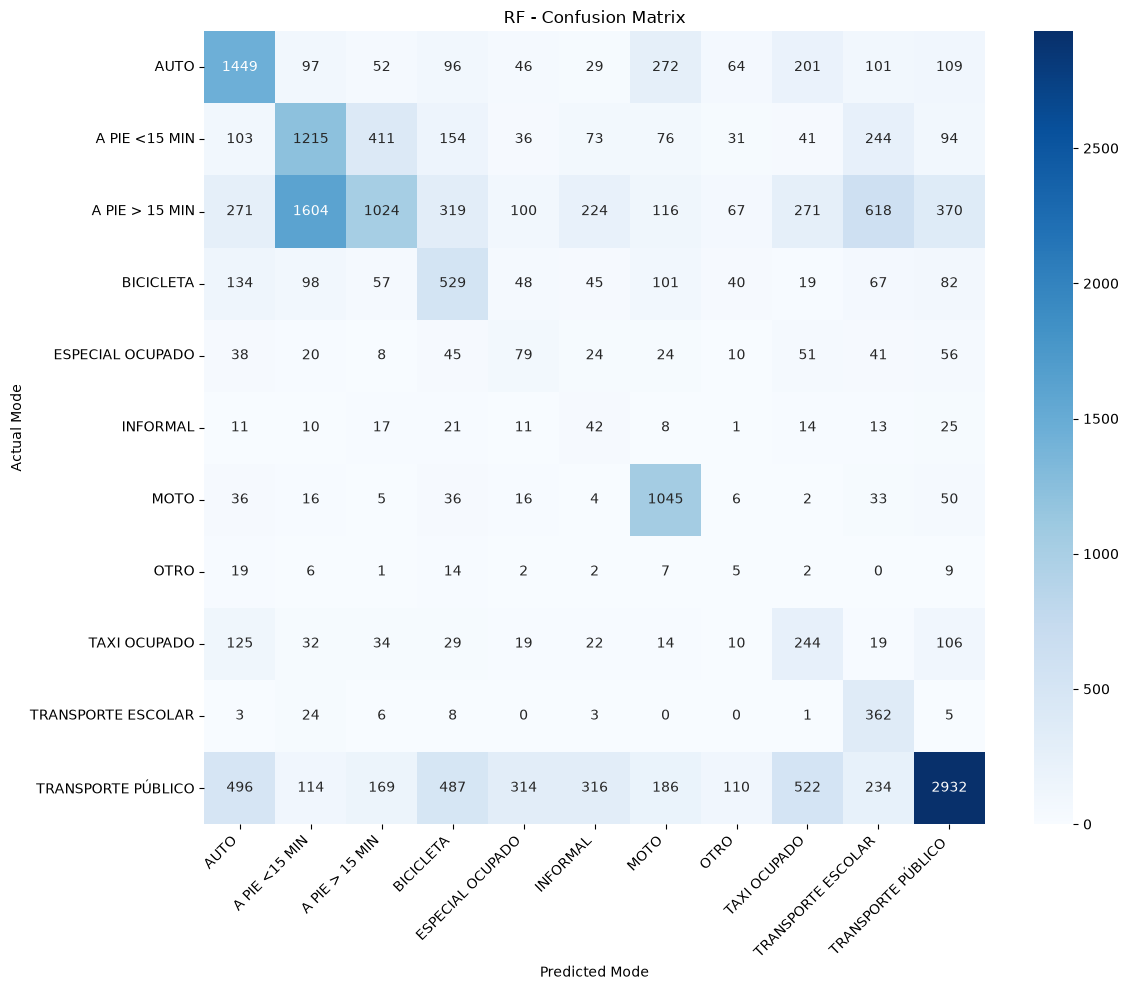

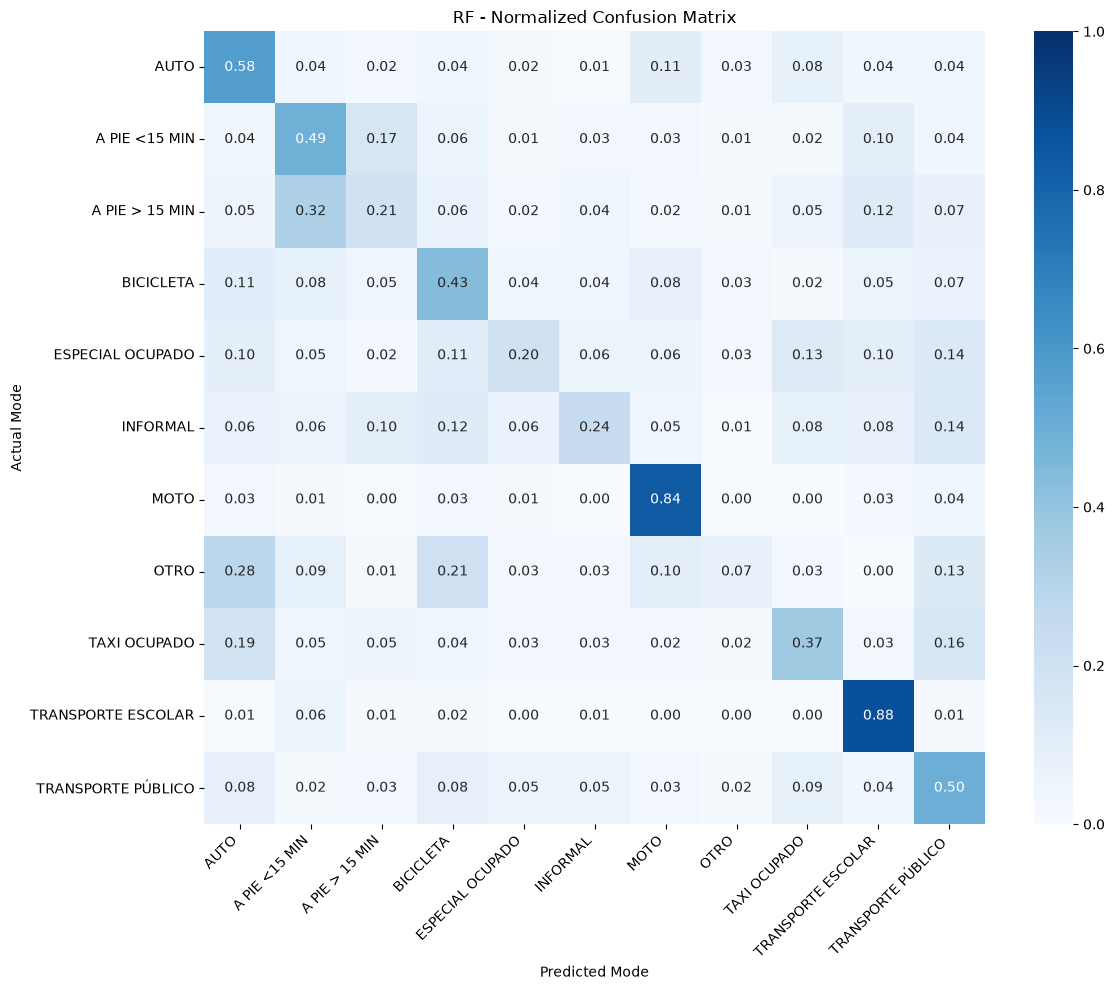

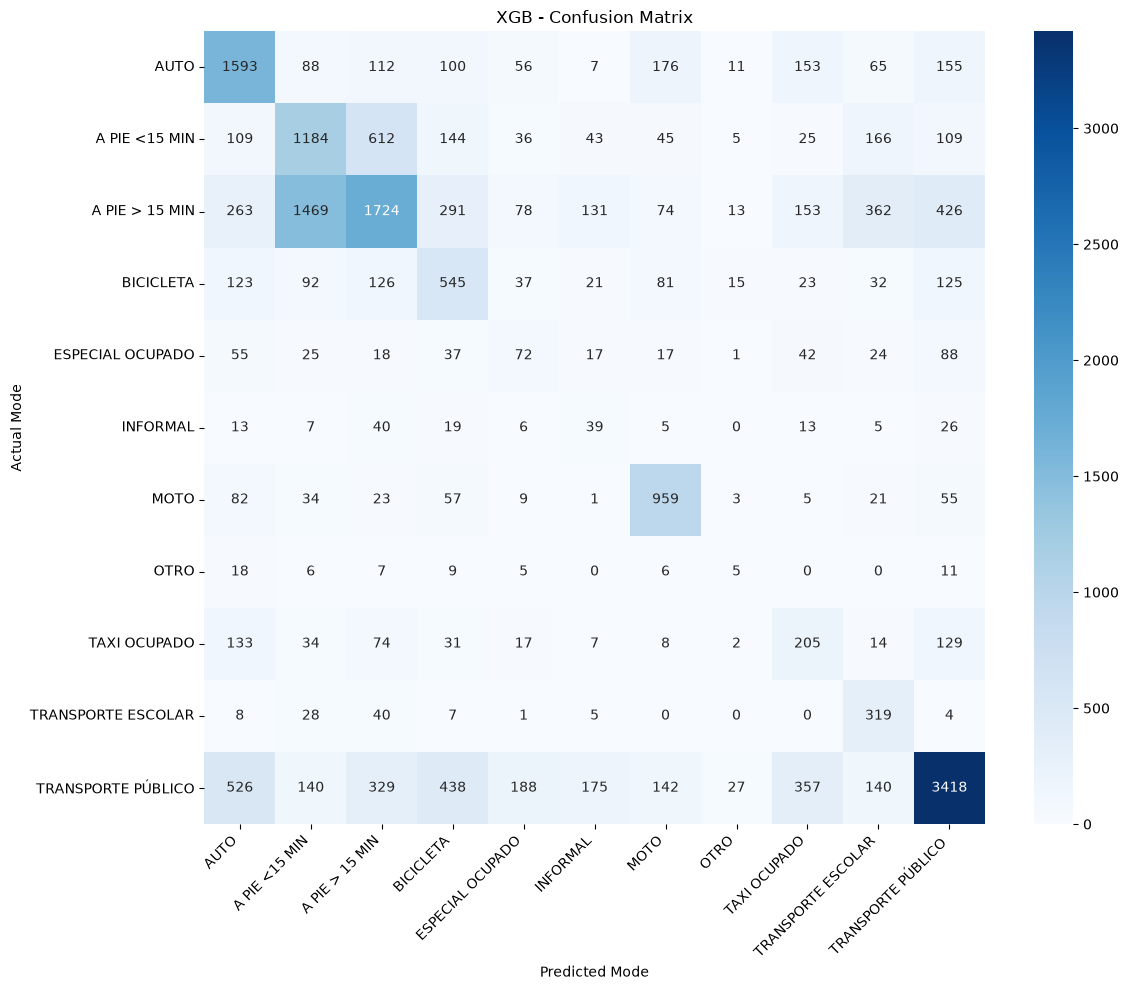

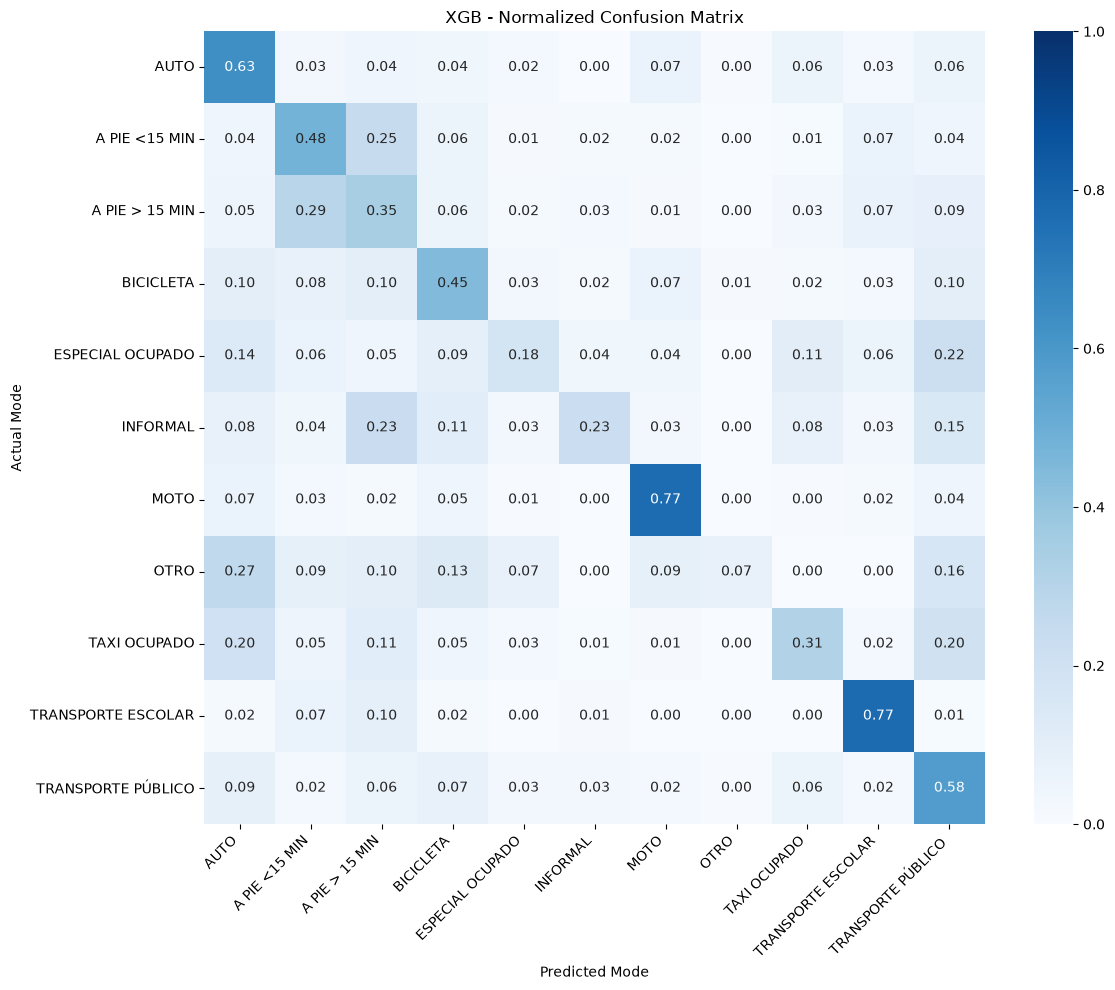

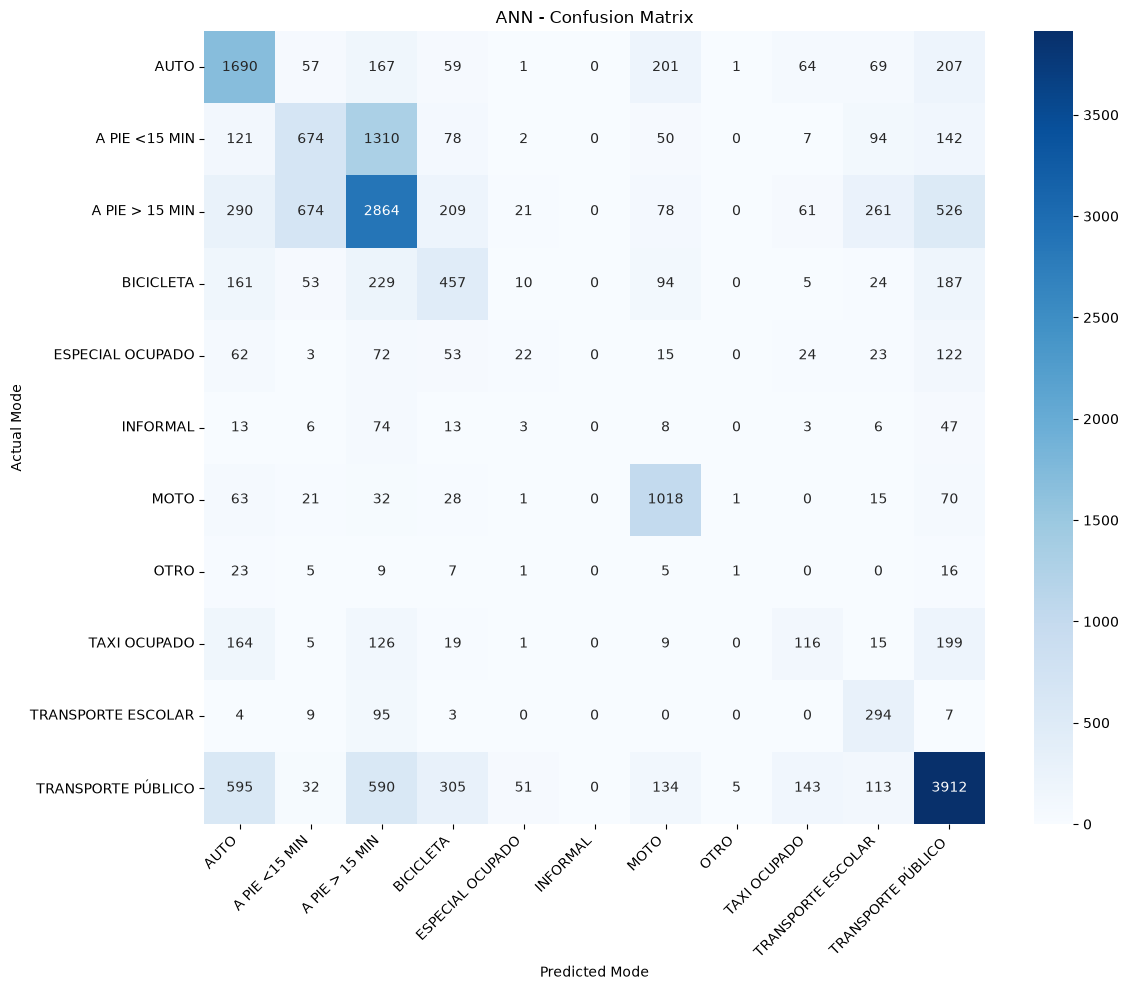

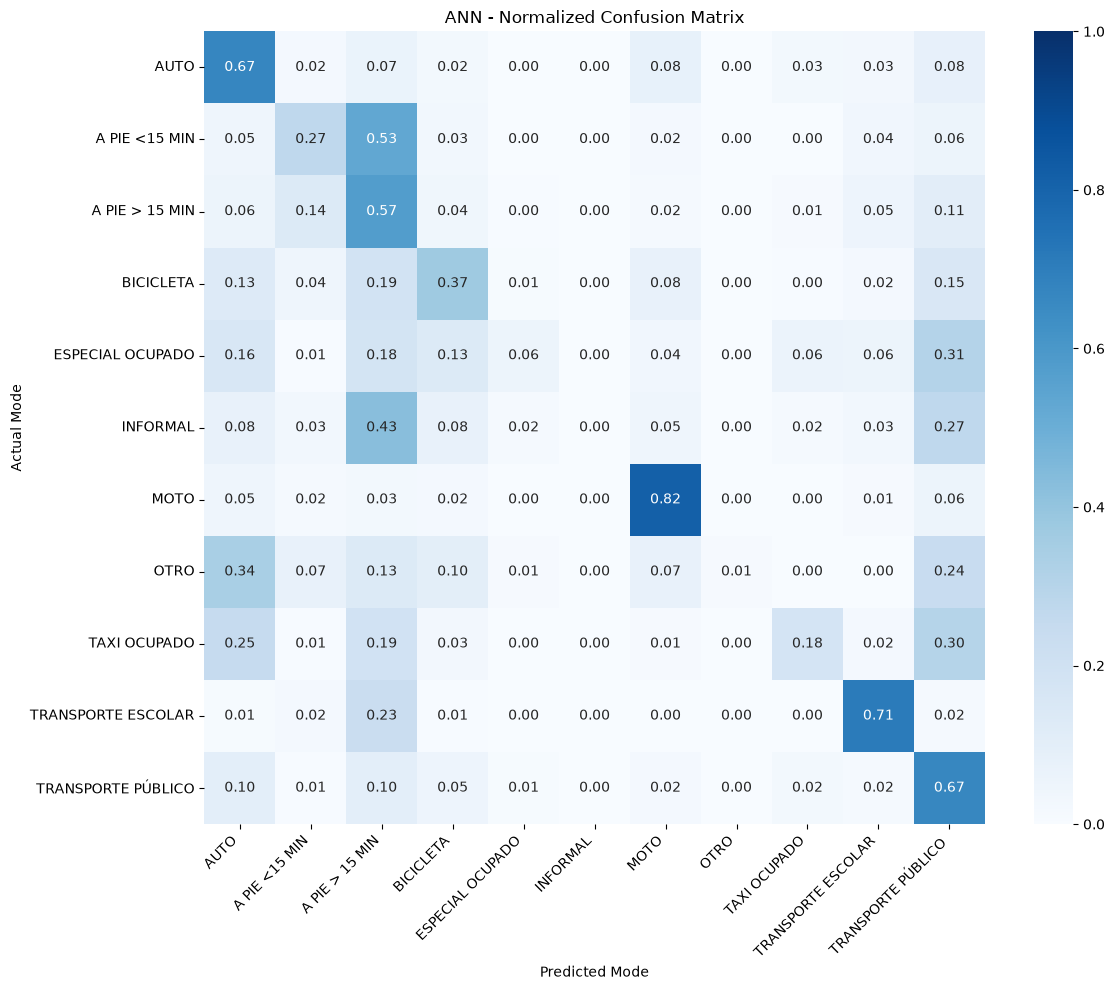

Confusion matrices generated and saved successfully.


In [47]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Define model predictions
model_predictions = {
    "RF": rf_predictions,
    "XGB": xgb_predictions,
    "ANN": ann_predictions
}

# Define class labels and output storage
class_labels = target_classes
confusion_results = {}

# Generate and save confusion matrices
for model_name, predictions in model_predictions.items():

    # Calculate absolute confusion matrix
    cm = confusion_matrix(
        y_test,
        predictions,
        labels=np.arange(len(class_labels))
    )

    # Normalize by actual class (row-wise)
    cm_normalized = confusion_matrix(
        y_test,
        predictions,
        labels=np.arange(len(class_labels)),
        normalize="true"
    )

    # Convert matrices to DataFrames
    cm_df = pd.DataFrame(
        cm,
        index=class_labels,
        columns=class_labels
    )

    cm_norm_df = pd.DataFrame(
        cm_normalized,
        index=class_labels,
        columns=class_labels
    )

    # Save matrices
    cm_df.to_csv(matrices_path / f"{model_name}_confusion_matrix.csv")
    cm_norm_df.to_csv(
        matrices_path / f"{model_name}_confusion_matrix_normalized.csv"
    )

    confusion_results[model_name] = {
        "counts": cm_df,
        "normalized": cm_norm_df
    }

    # Plot absolute confusion matrix
    plt.figure(figsize=(12, 10))
    sns.heatmap(
        cm_df,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_labels,
        yticklabels=class_labels
    )
    plt.title(f"{model_name} - Confusion Matrix")
    plt.xlabel("Predicted Mode")
    plt.ylabel("Actual Mode")
    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.savefig(
        figures_path / f"{model_name}_confusion_matrix.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
    plt.close()

    # Plot normalized confusion matrix
    plt.figure(figsize=(12, 10))
    sns.heatmap(
        cm_norm_df,
        annot=True,
        fmt=".2f",
        cmap="Blues",
        vmin=0,
        vmax=1,
        xticklabels=class_labels,
        yticklabels=class_labels
    )
    plt.title(f"{model_name} - Normalized Confusion Matrix")
    plt.xlabel("Predicted Mode")
    plt.ylabel("Actual Mode")
    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.savefig(
        figures_path / f"{model_name}_confusion_matrix_normalized.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
    plt.close()

print("Confusion matrices generated and saved successfully.")


**Confusion Matrix Analysis**

The confusion matrices provide additional insights into the classification behavior of Random Forest (RF), XGBoost, and the Artificial Neural Network (ANN). The row-normalized matrices are particularly useful because they show the proportion of observations from each actual mode assigned to each predicted category.

**Overall Classification Patterns**

The results reveal substantial differences across models and transportation modes. The ANN achieves the highest recall for AUTO (0.67), walking trips longer than 15 minutes (0.57), and public transportation (0.67). XGBoost performs best for bicycle trips (0.45), while Random Forest achieves the highest recall for walking trips shorter than 15 minutes (0.49), motorcycle trips (0.84), taxi trips (0.37), and school transportation (0.88).

These findings indicate that no single model consistently outperforms the others across all transportation categories.

**Walking Mode Classification**

A relevant source of classification error is the distinction between walking trips shorter and longer than 15 minutes. All three models confuse these categories, although the magnitude and direction of the errors differ.

The ANN correctly identifies 57% of walking trips longer than 15 minutes but only 27% of shorter walking trips. In contrast, RF and XGBoost achieve approximately 49% and 48% recall for shorter walking trips, respectively, but have greater difficulty identifying longer walking trips.

This pattern suggests that distinguishing walking duration categories remains challenging for the three classifiers.

**Public Transportation and Motorized Modes**

The ANN achieves the highest recall for public transportation (0.67), followed by XGBoost (0.58) and RF (0.50). Nevertheless, public transportation observations are still misclassified as AUTO, BICICLETA, and TAXI OCUPADO.

Motorcycle classification is comparatively strong across all models, with recall values ranging from 0.77 to 0.84. This suggests that the available explanatory variables provide useful information for distinguishing motorcycle trips.

**Minority Transportation Categories**

The weakest classification results are observed for INFORMAL, OTRO, and ESPECIAL OCUPADO. In particular, the ANN does not correctly identify any INFORMAL observations. Its confusion matrix also shows that the model does not assign any test observations to this category.

Although these results are consistent with potential challenges associated with class imbalance, the confusion matrices alone cannot establish that imbalance is the only cause of poor performance.

**Model-Specific Strengths and Limitations**

- **Random Forest:** Performs particularly well for motorcycle, school transportation, and shorter walking trips. However, its relatively low precision for some categories indicates a substantial number of false-positive predictions.
- **XGBoost:** Provides comparatively balanced classification performance across several categories and achieves the highest overall Macro-F1 score.
- **ANN:** Achieves the highest overall accuracy and the strongest recall for several major transportation categories. However, its performance is less consistent for some minority categories and shorter walking trips.

**Implications**

The confusion matrix analysis demonstrates that overall predictive performance does not fully capture the ability of machine learning models to distinguish individual transportation modes. Differences in class-level performance, particularly for walking categories and minority modes, should be considered when comparing predictive performance with the Multinomial Logit Model.

The next step is to investigate the distribution of model predictions and identify whether the classifiers systematically overpredict or underpredict specific transportation categories.

## 3. Interpretabilidad de modelos ML - SHAP

### 3.1 SHAP for XGBoost

In [48]:

import shap
import numpy as np
import pandas as pd

# Recover the fitted XGBoost pipeline components
xgb_preprocessor = xgb_model.named_steps["preprocessor"]
xgb_classifier = xgb_model.named_steps["classifier"]

# Transform the common test sample
X_test_xgb = xgb_preprocessor.transform(X_test)

# Recover transformed feature names
xgb_feature_names = xgb_preprocessor.get_feature_names_out()

# Create a reproducible sample for SHAP analysis
shap_sample_size = min(1000, X_test_xgb.shape[0])
rng = np.random.default_rng(42)
shap_indices = rng.choice(
    X_test_xgb.shape[0],
    size=shap_sample_size,
    replace=False
)

X_shap_xgb = X_test_xgb[shap_indices]

# Convert the sample into a DataFrame
X_shap_xgb_df = pd.DataFrame(
    X_shap_xgb.toarray() if hasattr(X_shap_xgb, "toarray") else X_shap_xgb,
    columns=xgb_feature_names
)

# Validate the SHAP input
assert X_shap_xgb_df.shape[1] == len(xgb_feature_names)
assert X_shap_xgb_df.isna().sum().sum() == 0

print(f"SHAP version: {shap.__version__}")
print(f"XGBoost sample: {X_shap_xgb_df.shape}")
print(f"Number of transformed features: {len(xgb_feature_names)}")
print("\nTransformed features:")
print(xgb_feature_names.tolist())


d:\JAIME_ALEJANDRO_GARCIA\01_ACADEMIC\2026_fall\508_Transportation_planning\Transportatio_Planning\508_TP_Proyect\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SHAP version: 0.54.1
XGBoost sample: (1000, 26)
Number of transformed features: 26

Transformed features:
['binary__has_car_license', 'binary__has_motorcycle_license', 'categorical__sexo_Intersexual', 'categorical__sexo_Mujer', 'categorical__estra_hg_2', 'categorical__estra_hg_3', 'categorical__estra_hg_4', 'categorical__estra_hg_5', 'categorical__estra_hg_6', 'categorical__estra_hg_No aplica', 'categorical__vehicle_availability_1', 'categorical__vehicle_availability_2+', 'categorical__purpose_group_ESCORT', 'categorical__purpose_group_HEALTH', 'categorical__purpose_group_HOME_RETURN', 'categorical__purpose_group_LEISURE', 'categorical__purpose_group_PERSONAL_ERRANDS', 'categorical__purpose_group_SOCIAL_RELIGIOUS', 'categorical__purpose_group_WORK', 'categorical__time_period_6_AM_PEAK', 'categorical__time_period_6_EVENING', 'categorical__time_period_6_OVERNIGHT', 'categorical__time_period_6_PM_OFF_PEAK', 'categorical__time_period_6_PM_PEAK', 'numerical__edad', 'numerical__zat_centroid_

In [49]:

# Initialize the SHAP TreeExplainer for XGBoost
xgb_explainer = shap.TreeExplainer(xgb_classifier)

# Calculate SHAP values for the selected test sample
xgb_shap_values = xgb_explainer(
    X_shap_xgb
)

# Inspect the resulting SHAP dimensions
print("SHAP values shape:", xgb_shap_values.values.shape)
print("Base values shape:", np.asarray(xgb_shap_values.base_values).shape)
print("Feature names:", len(xgb_feature_names))
print("Target classes:", len(target_classes))

# Validate the multiclass SHAP output
assert xgb_shap_values.values.shape[0] == shap_sample_size
assert xgb_shap_values.values.shape[1] == len(xgb_feature_names)
assert xgb_shap_values.values.shape[2] == len(target_classes)

print("\nXGBoost SHAP values calculated successfully.")


SHAP values shape: (1000, 26, 11)
Base values shape: (1000, 11)
Feature names: 26
Target classes: 11

XGBoost SHAP values calculated successfully.


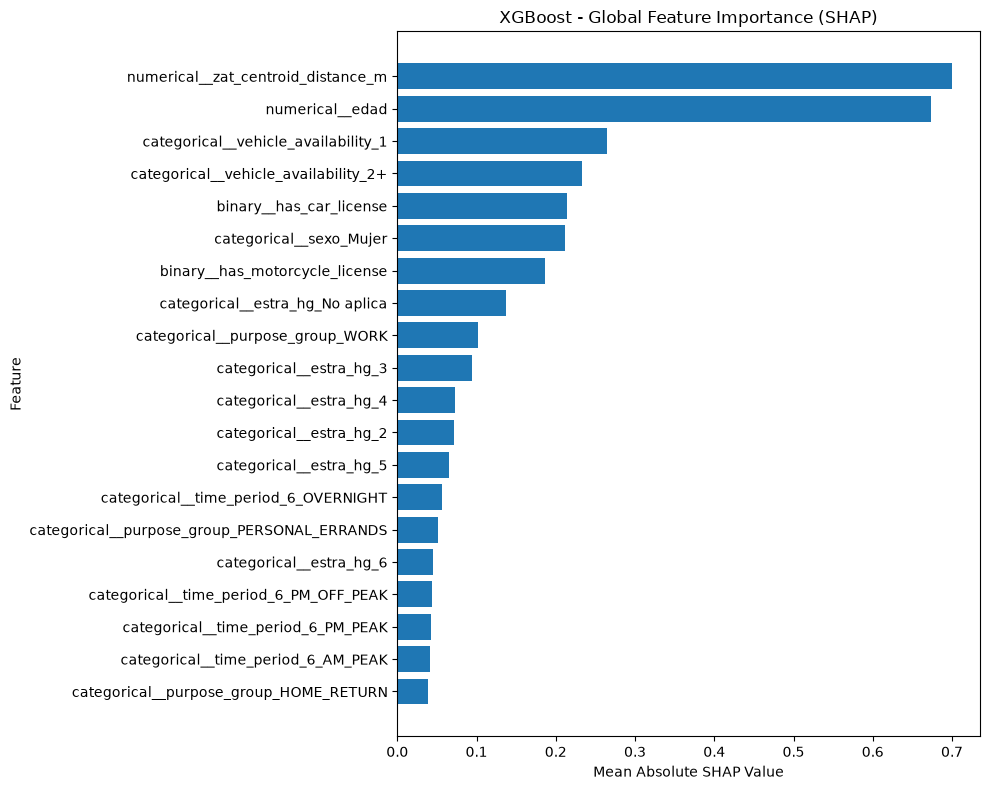

Top 15 XGBoost features:


,Feature,Mean_Absolute_SHAP
0,numerical__zat_centroid_distance_m,0.700321
1,numerical__edad,0.673355
2,categorical__vehicle_availability_1,0.264154
3,categorical__vehicle_availability_2+,0.232544
4,binary__has_car_license,0.214027
5,categorical__sexo_Mujer,0.211839
6,binary__has_motorcycle_license,0.186093
7,categorical__estra_hg_No aplica,0.136651
8,categorical__purpose_group_WORK,0.102429
9,categorical__estra_hg_3,0.093897


In [50]:

import matplotlib.pyplot as plt

# Calculate global mean absolute SHAP values across observations and classes
xgb_global_importance = np.abs(
    xgb_shap_values.values
).mean(axis=(0, 2))

# Create and sort the global importance table
xgb_importance_df = pd.DataFrame({
    "Feature": xgb_feature_names,
    "Mean_Absolute_SHAP": xgb_global_importance
}).sort_values(
    "Mean_Absolute_SHAP",
    ascending=False
).reset_index(drop=True)

# Save global importance results
xgb_importance_df.to_csv(
    tables_path / "XGB_SHAP_global_importance.csv",
    index=False
)

# Plot the top 20 most important features
top_features = xgb_importance_df.head(20).sort_values(
    "Mean_Absolute_SHAP",
    ascending=True
)

plt.figure(figsize=(10, 8))
plt.barh(
    top_features["Feature"],
    top_features["Mean_Absolute_SHAP"]
)
plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Feature")
plt.title("XGBoost - Global Feature Importance (SHAP)")
plt.tight_layout()
plt.savefig(
    figures_path / "XGB_SHAP_global_importance.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

print("Top 15 XGBoost features:")
display(xgb_importance_df.head(15))


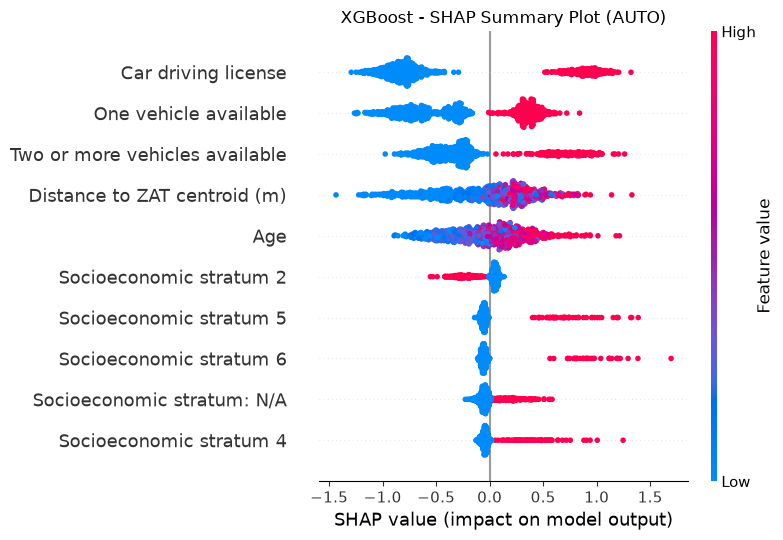

Top 10 features for AUTO:


,Feature,Mean_Absolute_SHAP
0,binary__has_car_license,0.844789
1,categorical__vehicle_availability_1,0.515718
2,categorical__vehicle_availability_2+,0.448695
3,numerical__zat_centroid_distance_m,0.341175
4,numerical__edad,0.276006
5,categorical__estra_hg_2,0.097726
6,categorical__estra_hg_5,0.095550
7,categorical__estra_hg_6,0.088687
8,categorical__estra_hg_No aplica,0.084858
9,categorical__estra_hg_4,0.075743


In [52]:

# Select AUTO and calculate its feature importance
class_name = "AUTO"
class_idx = target_classes.index(class_name)

auto_shap_values = xgb_shap_values.values[:, :, class_idx]

auto_importance = np.abs(auto_shap_values).mean(axis=0)

auto_importance_df = pd.DataFrame({
    "Feature": xgb_feature_names,
    "Mean_Absolute_SHAP": auto_importance
}).sort_values(
    "Mean_Absolute_SHAP",
    ascending=False
).reset_index(drop=True)

# Select the top 10 features for visualization
top_10_auto = auto_importance_df.head(10)["Feature"].tolist()

# Define readable feature labels
feature_labels = {
    "binary__has_car_license": "Car driving license",
    "binary__has_motorcycle_license": "Motorcycle driving license",
    "categorical__sexo_Intersexual": "Sex: Intersexual",
    "categorical__sexo_Mujer": "Sex: Female",
    "categorical__estra_hg_2": "Socioeconomic stratum 2",
    "categorical__estra_hg_3": "Socioeconomic stratum 3",
    "categorical__estra_hg_4": "Socioeconomic stratum 4",
    "categorical__estra_hg_5": "Socioeconomic stratum 5",
    "categorical__estra_hg_6": "Socioeconomic stratum 6",
    "categorical__estra_hg_No aplica": "Socioeconomic stratum: N/A",
    "categorical__vehicle_availability_1": "One vehicle available",
    "categorical__vehicle_availability_2+": "Two or more vehicles available",
    "categorical__purpose_group_ESCORT": "Trip purpose: Escort",
    "categorical__purpose_group_HEALTH": "Trip purpose: Health",
    "categorical__purpose_group_HOME_RETURN": "Trip purpose: Home return",
    "categorical__purpose_group_LEISURE": "Trip purpose: Leisure",
    "categorical__purpose_group_PERSONAL_ERRANDS": "Trip purpose: Personal errands",
    "categorical__purpose_group_SOCIAL_RELIGIOUS": "Trip purpose: Social/Religious",
    "categorical__purpose_group_WORK": "Trip purpose: Work",
    "categorical__time_period_6_AM_PEAK": "Time period: AM peak",
    "categorical__time_period_6_EVENING": "Time period: Evening",
    "categorical__time_period_6_OVERNIGHT": "Time period: Overnight",
    "categorical__time_period_6_PM_OFF_PEAK": "Time period: PM off-peak",
    "categorical__time_period_6_PM_PEAK": "Time period: PM peak",
    "numerical__edad": "Age",
    "numerical__zat_centroid_distance_m": "Distance to ZAT centroid (m)"
}

# Build a named SHAP explanation for the selected features
selected_indices = [
    list(xgb_feature_names).index(feature)
    for feature in top_10_auto
]

auto_shap_explanation = shap.Explanation(
    values=auto_shap_values[:, selected_indices],
    base_values=xgb_shap_values.base_values[:, class_idx],
    data=X_shap_xgb_df[top_10_auto].values,
    feature_names=[
        feature_labels.get(feature, feature)
        for feature in top_10_auto
    ]
)

# Generate the AUTO SHAP beeswarm plot
plt.figure(figsize=(11, 7))
shap.plots.beeswarm(
    auto_shap_explanation,
    max_display=10,
    show=False
)

plt.title("XGBoost - SHAP Summary Plot (AUTO)")
plt.xlabel("SHAP value (impact on model output)")
plt.tight_layout()
plt.savefig(
    figures_path / "XGB_SHAP_beeswarm_AUTO.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

print("Top 10 features for AUTO:")
display(auto_importance_df.head(10))


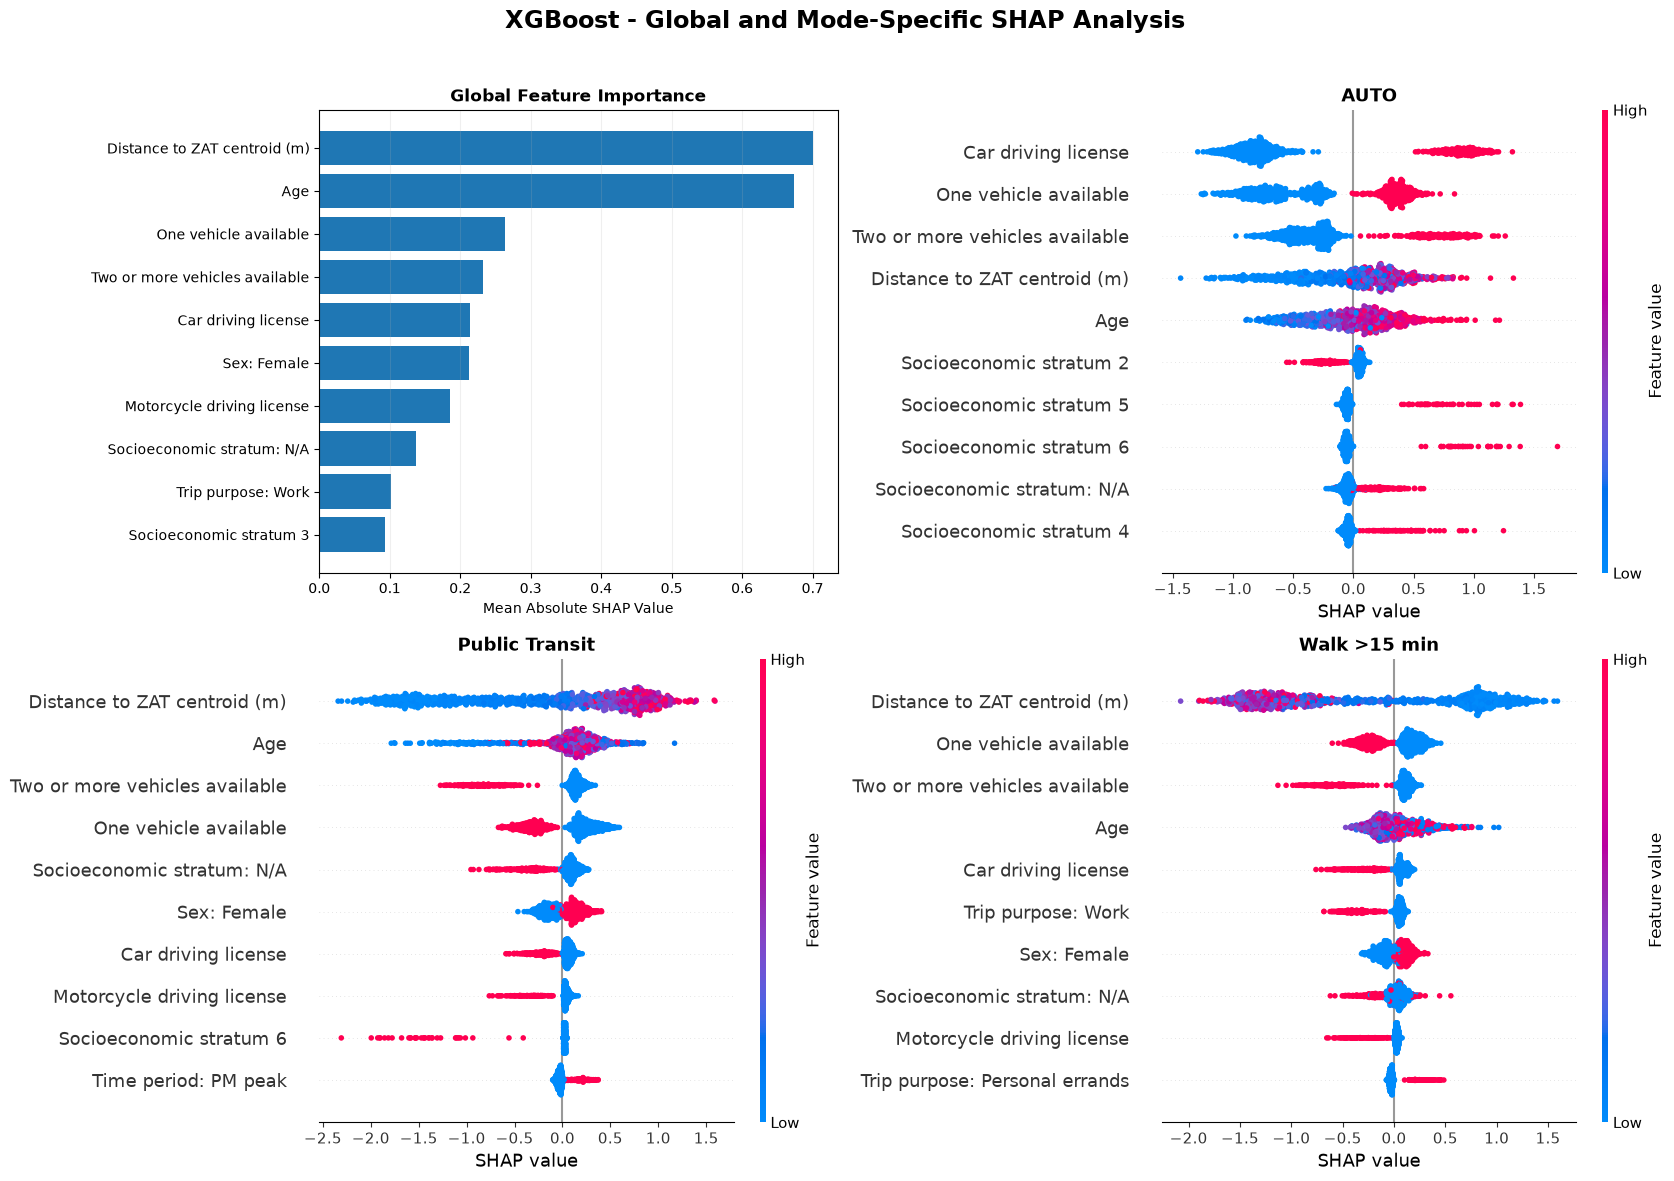

XGBoost executive SHAP figure and global table saved.


,Feature,Feature_Label,Mean_Absolute_SHAP
0,numerical__zat_centroid_distance_m,Distance to ZAT centroid (m),0.700321
1,numerical__edad,Age,0.673355
2,categorical__vehicle_availability_1,One vehicle available,0.264154
3,categorical__vehicle_availability_2+,Two or more vehicles available,0.232544
4,binary__has_car_license,Car driving license,0.214027
5,categorical__sexo_Mujer,Sex: Female,0.211839
6,binary__has_motorcycle_license,Motorcycle driving license,0.186093
7,categorical__estra_hg_No aplica,Socioeconomic stratum: N/A,0.136651
8,categorical__purpose_group_WORK,Trip purpose: Work,0.102429
9,categorical__estra_hg_3,Socioeconomic stratum 3,0.093897


In [54]:

# Define the selected alternatives
selected_modes = {
    "AUTO": "AUTO",
    "Public Transit": "TRANSPORTE PÚBLICO",
    "Walk >15 min": "A PIE > 15 MIN"
}

# Calculate global mean absolute SHAP importance
global_importance = np.abs(
    xgb_shap_values.values
).mean(axis=(0, 2))

# Create the complete global importance table
xgb_global_df = pd.DataFrame({
    "Feature": xgb_feature_names,
    "Feature_Label": [
        feature_labels.get(f, f) for f in xgb_feature_names
    ],
    "Mean_Absolute_SHAP": global_importance
}).sort_values(
    "Mean_Absolute_SHAP",
    ascending=False
).reset_index(drop=True)

# Save the complete global importance table
xgb_global_df.to_csv(
    tables_path / "XGB_SHAP_global_importance.csv",
    index=False
)

# Create the executive 2x2 figure
fig, axes = plt.subplots(2, 2, figsize=(17, 12))
axes = axes.flatten()

# Panel 1: Global feature importance
global_top = xgb_global_df.head(10).sort_values(
    "Mean_Absolute_SHAP",
    ascending=True
)

axes[0].barh(
    global_top["Feature_Label"],
    global_top["Mean_Absolute_SHAP"]
)
axes[0].set_title("Global Feature Importance", fontweight="bold")
axes[0].set_xlabel("Mean Absolute SHAP Value")
axes[0].set_ylabel("")
axes[0].grid(axis="x", alpha=0.2)

# Panels 2-4: Mode-specific SHAP beeswarm plots
for ax, (panel_name, class_name) in zip(
    axes[1:], selected_modes.items()
):
    class_idx = target_classes.index(class_name)

    # Extract SHAP values for the selected alternative
    mode_shap = xgb_shap_values.values[:, :, class_idx]

    # Identify the top 10 features for this alternative
    mode_importance = np.abs(mode_shap).mean(axis=0)
    top_indices = np.argsort(mode_importance)[-10:]

    # Build the named SHAP explanation
    mode_explanation = shap.Explanation(
        values=mode_shap[:, top_indices],
        base_values=xgb_shap_values.base_values[:, class_idx],
        data=X_shap_xgb_df.iloc[:, top_indices].values,
        feature_names=[
            feature_labels.get(xgb_feature_names[i], xgb_feature_names[i])
            for i in top_indices
        ]
    )

    # Generate the beeswarm plot
    plt.sca(ax)
    shap.plots.beeswarm(
        mode_explanation,
        max_display=10,
        show=False,
        plot_size=None
    )

    ax.set_title(panel_name, fontweight="bold", fontsize=13)
    ax.set_xlabel("SHAP value")

# Apply final layout and save
fig.suptitle(
    "XGBoost - Global and Mode-Specific SHAP Analysis",
    fontsize=17,
    fontweight="bold"
)
plt.tight_layout(rect=[0, 0, 1, 0.96])

plt.savefig(
    figures_path / "XGB_SHAP_executive.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

print("XGBoost executive SHAP figure and global table saved.")
display(xgb_global_df.head(10))


### 3.2 SHAP for RF

In [1]:
# Restore imports and project paths after kernel restart
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import joblib
import torch
from pathlib import Path
import time

# Restore project directories
project_path = Path(
    r"D:\JAIME_ALEJANDRO_GARCIA\01_ACADEMIC\2026_fall\508_Transportation_planning\Transportatio_Planning\508_TP_Proyect"
)

ml_path = project_path / "outputs" / "ML_models"
figures_path = project_path / "outputs" / "figures"
tables_path = project_path / "outputs" / "tables"
matrices_path = project_path / "outputs" / "matrices"

print("Environment restored.")
print("SHAP version:", shap.__version__)

d:\JAIME_ALEJANDRO_GARCIA\01_ACADEMIC\2026_fall\508_Transportation_planning\Transportatio_Planning\508_TP_Proyect\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Environment restored.
SHAP version: 0.54.1


In [2]:

# Load the saved Random Forest pipeline
rf_model = joblib.load(ml_path / "RF_final_model.joblib")

# Load the analytical dataset
df_base = pd.read_csv(
    project_path / "data" / "analytical" / "df_base.csv"
)

# Inspect the model and dataset
rf_preprocessor = rf_model.named_steps["preprocessor"]
rf_classifier = rf_model.named_steps["classifier"]

print("Random Forest loaded successfully.")
print("Pipeline steps:", list(rf_model.named_steps.keys()))
print("Analytical dataset shape:", df_base.shape)
print("RF number of features:", len(rf_preprocessor.get_feature_names_out()))
print("RF number of classes:", len(rf_classifier.classes_))


Random Forest loaded successfully.
Pipeline steps: ['preprocessor', 'classifier']
Analytical dataset shape: (100143, 19)
RF number of features: 26
RF number of classes: 11


C:\Users\ASUS\AppData\Local\Temp\ipykernel_20532\3623005595.py:5: DtypeWarning: Columns (6) have mixed types. Specify dtype option on import or set low_memory=False.
  df_base = pd.read_csv(


In [3]:
# Inspect saved modeling artifacts and analysis files
for folder in [ml_path, project_path / "outputs" / "Mode_choice_analysis"]:
    print(f"\n--- {folder.name} ---")
    if folder.exists():
        for file in sorted(folder.iterdir()):
            print(file.name)
    else:
        print("Folder not found.")


--- ML_models ---
ANN_final_metadata.json
ANN_final_model.pth
ANN_final_preprocessor.joblib
ANN_optimizer_learning_rate_comparison.csv
MLP_architecture_CV_results.csv
MLP_architecture_CV_summary.csv
RF_final_feature_importance.csv
RF_final_metadata.json
RF_final_model.joblib
XGB_final_feature_importance.csv
XGB_final_metadata.json
XGB_final_model.joblib

--- Mode_choice_analysis ---
MNL_B6_classification_report.csv
MNL_B6_test_metrics.csv


In [4]:
# Inspect model metadata to recover the original data split configuration
import json

for model_name in ["RF", "XGB", "ANN"]:
    metadata_file = ml_path / f"{model_name}_final_metadata.json"

    with open(metadata_file, "r", encoding="utf-8") as f:
        metadata = json.load(f)

    print(f"\n--- {model_name} metadata ---")
    for key, value in metadata.items():
        print(f"{key}: {value}")


--- RF metadata ---
model: Random Forest
status: Final
features: ['has_car_license', 'has_motorcycle_license', 'sexo', 'estra_hg', 'vehicle_availability', 'purpose_group', 'time_period_6', 'edad', 'zat_centroid_distance_m']
target: modo_principal_agrupado
target_classes: ['AUTO', 'A PIE <15 MIN', 'A PIE > 15 MIN', 'BICICLETA', 'ESPECIAL OCUPADO', 'INFORMAL', 'MOTO', 'OTRO', 'TAXI OCUPADO', 'TRANSPORTE ESCOLAR', 'TRANSPORTE PÚBLICO']
hyperparameters: {'max_depth': 25, 'min_samples_leaf': 5, 'max_features': 'sqrt'}
n_estimators: 300
class_weight: balanced
random_state: 42
cv_macro_f1: 0.3339
cv_log_loss: 1.5619
test_metrics: {'Accuracy': 0.4456538019871187, 'Macro-F1': 0.34181883660776463, 'Log Loss': 1.5390699114826936}

--- XGB metadata ---
model: XGBoost
status: Final
features: ['has_car_license', 'has_motorcycle_license', 'sexo', 'estra_hg', 'vehicle_availability', 'purpose_group', 'time_period_6', 'edad', 'zat_centroid_distance_m']
target: modo_principal_agrupado
target_classes: ['

In [5]:
# Search project notebooks and Python scripts for the original train-test split
import re

search_terms = [
    "GroupShuffleSplit",
    "StratifiedGroupKFold",
    "train_test_split",
    "key_pers",
    "random_state",
    "df_test"
]

source_files = list(project_path.rglob("*.ipynb")) + list(project_path.rglob("*.py"))

for file in source_files:
    if any(part in file.parts for part in [".git", ".venv", "venv"]):
        continue

    try:
        content = file.read_text(encoding="utf-8", errors="ignore")
        matches = [
            (i, line.strip())
            for i, line in enumerate(content.splitlines(), start=1)
            if any(term.lower() in line.lower() for term in search_terms)
        ]

        if matches:
            print(f"\n--- {file.relative_to(project_path)} ---")
            for line_no, line in matches[:30]:
                print(f"{line_no}: {line[:250]}")
    except Exception:
        pass


--- notebooks\03_mode_choice_data_audit.ipynb ---
50: "assert not any(column in {'key_viaje', 'key_hg', 'key_persona', 'cod_per', 'cod_pers'} for frame in [relation_audit, field_profile, duplicate_comparison] for column in frame.columns)\n",

--- notebooks\04_mode_choice_join_preview.ipynb ---
32: "assert preview['persona__key_persona'].ne('').all()\n",
88: "    'key_hg': 'Technical household identifier.', 'key_pers': 'Person identifier linked to the trip.',\n",
89: "    'key_pers_viaja': 'Alternate identifier for the traveling person.', 'key_viaje': 'Unique technical trip identifier.',\n",
143: "Keep one row per `key_viaje`. Link trips to people with `key_pers = key_persona` and to households with `key_hg`. Aggregate one-to-many vehicle records to household level before joining. Do not join raw stage rows directly to trips. Keep both observ
196: "assert people['key_persona'].notna().all() and people['key_persona'].is_unique\n",
202: "full = trips.merge(people_join, left_on='key_pers'

In [ ]:

# Verify that Random Forest uses the same transformed features
rf_preprocessor = rf_model.named_steps["preprocessor"]
rf_classifier = rf_model.named_steps["classifier"]

rf_feature_names = list(rf_preprocessor.get_feature_names_out())

assert rf_feature_names == list(X_shap_xgb_df.columns), (
    "The transformed feature names or order differ between RF and XGBoost."
)

assert len(X_shap_xgb_df) == 1000
assert len(rf_classifier.classes_) == len(target_classes)

# Calculate SHAP values using the trained Random Forest classifier
rf_explainer = shap.TreeExplainer(rf_classifier)
rf_shap_values = rf_explainer(X_shap_xgb_df)

print("RF SHAP values shape:", rf_shap_values.values.shape)
print("RF base values shape:", np.asarray(rf_shap_values.base_values).shape)

# Calculate global mean absolute SHAP importance
rf_global_importance = np.abs(
    rf_shap_values.values
).mean(axis=(0, 2))

# Create and save the complete global importance table
rf_global_df = pd.DataFrame({
    "Feature": rf_feature_names,
    "Feature_Label": [
        feature_labels.get(f, f) for f in rf_feature_names
    ],
    "Mean_Absolute_SHAP": rf_global_importance
}).sort_values(
    "Mean_Absolute_SHAP",
    ascending=False
).reset_index(drop=True)

rf_global_df.to_csv(
    tables_path / "RF_SHAP_global_importance.csv",
    index=False
)

# Define the selected alternatives
selected_modes = {
    "AUTO": "AUTO",
    "Public Transit": "TRANSPORTE PÚBLICO",
    "Walk >15 min": "A PIE > 15 MIN"
}

# Create the executive 2x2 figure
fig, axes = plt.subplots(2, 2, figsize=(17, 12))
axes = axes.flatten()

# Panel 1: Global feature importance
global_top = rf_global_df.head(10).sort_values(
    "Mean_Absolute_SHAP",
    ascending=True
)

axes[0].barh(
    global_top["Feature_Label"],
    global_top["Mean_Absolute_SHAP"]
)
axes[0].set_title("Global Feature Importance", fontweight="bold")
axes[0].set_xlabel("Mean Absolute SHAP Value")
axes[0].set_ylabel("")
axes[0].grid(axis="x", alpha=0.2)

# Panels 2-4: Mode-specific SHAP beeswarm plots
for ax, (panel_name, class_name) in zip(
    axes[1:], selected_modes.items()
):
    class_idx = target_classes.index(class_name)

    # Extract SHAP values for the selected alternative
    mode_shap = rf_shap_values.values[:, :, class_idx]
    mode_importance = np.abs(mode_shap).mean(axis=0)
    top_indices = np.argsort(mode_importance)[-10:]

    # Select base values for the selected alternative
    base_values = np.asarray(rf_shap_values.base_values)
    if base_values.ndim == 2:
        mode_base_values = base_values[:, class_idx]
    else:
        mode_base_values = base_values[class_idx]

    # Build the named SHAP explanation
    mode_explanation = shap.Explanation(
        values=mode_shap[:, top_indices],
        base_values=mode_base_values,
        data=X_shap_xgb_df.iloc[:, top_indices].values,
        feature_names=[
            feature_labels.get(rf_feature_names[i], rf_feature_names[i])
            for i in top_indices
        ]
    )

    # Generate the beeswarm plot
    plt.sca(ax)
    shap.plots.beeswarm(
        mode_explanation,
        max_display=10,
        show=False,
        plot_size=None
    )

    ax.set_title(panel_name, fontweight="bold", fontsize=13)
    ax.set_xlabel("SHAP value")

# Apply final layout and save
fig.suptitle(
    "Random Forest - Global and Mode-Specific SHAP Analysis",
    fontsize=17,
    fontweight="bold"
)
plt.tight_layout(rect=[0, 0, 1, 0.96])

plt.savefig(
    figures_path / "RF_SHAP_executive.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

print("Random Forest SHAP analysis completed.")
display(rf_global_df.head(10))
